In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os
sys.path.append(os.path.abspath('../src'))
import simpRepair
import simplification

In [3]:
import sys
import os
sys.path.append(os.path.abspath('../src'))
import matplotlib.pyplot as plt
from IPython.display import HTML
import matplotlib.animation
import numpy as np

from torchvision.io import read_image
from pathlib import Path
import torchvision.transforms.functional as F

from torchvision.models.segmentation import fcn_resnet50

from torchvision.transforms.functional import convert_image_dtype
from torchvision.transforms.functional import crop
from torchvision.transforms.functional import resize

import torch
from torchvision.utils import draw_segmentation_masks

from torchvision.transforms import GaussianBlur
from torchvision.transforms.v2 import GaussianNoise
import numpy as np
import pywt
from skimage.measure import shannon_entropy, blur_effect
import cv2
import imagecodecs
import simplification
import visualization_utils

In [4]:
import glob
images = glob.glob('/mnt/extraStorage/coco_official_test/test2017/*.jpg')
print(images[0])

/mnt/extraStorage/coco_official_test/test2017/000000566818.jpg


/mnt/extraStorage/coco_official_test/test2017/000000408643.jpg


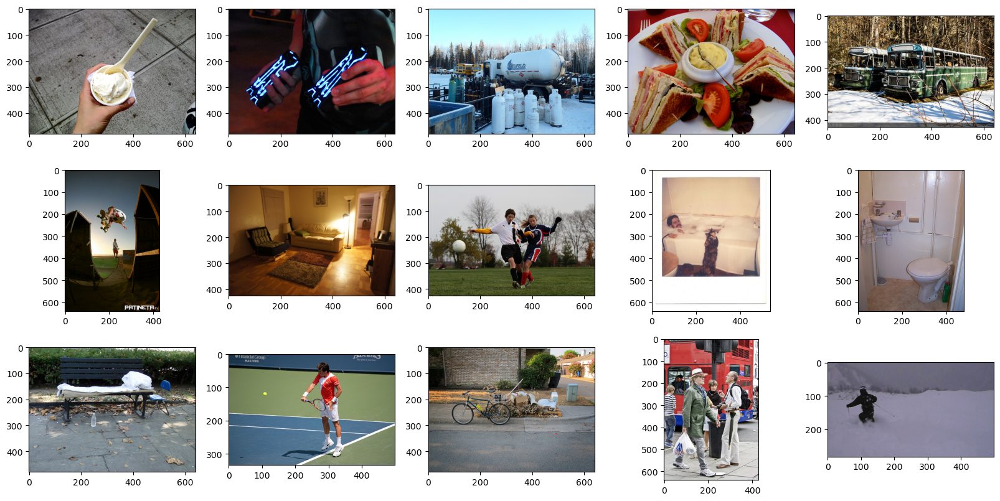

In [5]:
t = 28
# img = crop(img, 20, 20, 280, 400)
plt.figure(figsize=(20, 10))
for i in range(15):
    img = read_image(str(images[i + 15 * t]))[:3, :, :]
    plt.subplot(3, 5, i + 1)
    plt.imshow(img.permute(1, 2, 0))

print(images[9 + 15 * 29])

In [6]:
import json

with open('/mnt/extraStorage/coco_official_test/lvis_v1_image_info_test_dev.json', 'r') as handle:
    parsed = json.load(handle)

print(json.dumps(parsed, indent=4))

{
    "info": {
        "contributor": "Agrim Gupta, Piotr Dollar, Ross Girshick",
        "version": "1",
        "year": 2020,
        "url": "http://lvisdataset.org",
        "description": "LVIS 2020 Dataset"
    },
    "annotations": [],
    "images": [
        {
            "id": 466319,
            "width": 640,
            "license": 6,
            "coco_url": "http://images.cocodataset.org/test2017/000000466319.jpg",
            "date_captured": "2013-11-14 11:04:33",
            "height": 480
        },
        {
            "id": 413171,
            "width": 500,
            "license": 3,
            "coco_url": "http://images.cocodataset.org/test2017/000000413171.jpg",
            "date_captured": "2013-11-14 16:40:04",
            "height": 333
        },
        {
            "id": 186384,
            "width": 424,
            "license": 4,
            "coco_url": "http://images.cocodataset.org/test2017/000000186384.jpg",
            "date_captured": "2013-11-14 17:05:50"

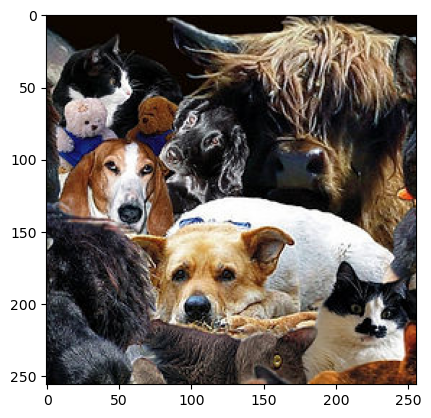

In [63]:
# img = read_image(
#     str(images[5 + 15 * 51]))[:3, :, :]
# plt.imshow(img.permute(1, 2, 0))

# img = read_image(
#     str(images[10 + 15 * 124]))[:3, :, :]
# plt.imshow(img.permute(1, 2, 0))
# img = resize(img, (300))
# img = crop(img, 0, 100, 256, 256)

# img = read_image(
#     str(images[6 + 15 * 127]))[:3, :, :]
# plt.imshow(img.permute(1, 2, 0))
# img = resize(img, (300))
# img = crop(img, 0, 100, 256, 256)


# print(images[1 + 15 * 98])
# img = read_image(
#     str(images[1 + 15 * 98]))[:3, :, :]
# img = crop(img, 50, 10, 256, 256)


# /mnt/extraStorage/coco_official_test/test2017/000000387001.jpg
img = read_image(
    str("/mnt/extraStorage/coco_official_test/test2017/000000387001.jpg"))[:3, :, :]
img = crop(img, 0, 100, 256, 256)

# print(images[8 + 15 * 121])
# img = read_image(
#     str(images[8 + 15 * 121]))[:3, :, :]
# img = crop(img, 70, 80, 256, 256)

plt.imshow(img.permute(1, 2, 0))

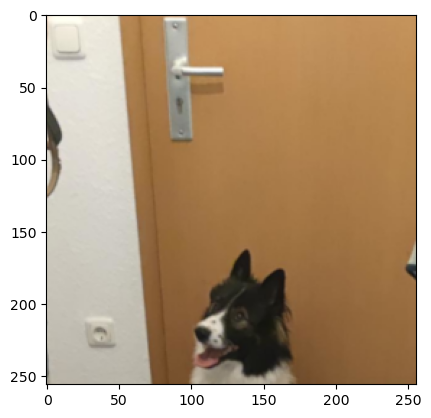

In [81]:
# Cat dog bottle
# img = read_image(
#     str(Path('/mnt/extraStorage/example_images_for_coco') / 'testcoco3.png'))[:3, :, :]
# img = crop(img, 50, 90, 350, 350)


# img = read_image(
#     str(Path('/mnt/extraStorage/example_images_for_coco') / 'cow_horse.jpg'))[:3, :, :]
# img = crop(img, 160, 130, 300, 300)

# img = read_image(
#     str(Path('/mnt/extraStorage/example_images_for_coco') / 'testcoco3.png'))[:3, :, :]
# img = crop(img, 60, 30, 280, 280)

# img = resize(img, (img.shape[1] // 2, img.shape[2] // 2))

img = read_image(
    str(Path('/mnt/extraStorage/example_images_for_coco') / 'testcoco.png'))[:3, :, :]
img = crop(img, 10, 50, 256, 256)


plt.imshow(img.permute(1, 2, 0))

In [82]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = fcn_resnet50(pretrained=True, progress=False).to(device)
model = model.eval()
for param in model.parameters():
    param.requires_grad_(False)

img = convert_image_dtype(img, dtype=torch.float).to(device)
normalized_img = F.normalize(img, mean=(
    0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
output = model(normalized_img.unsqueeze(0))['out']
print(output.shape, output.min().item(), output.max().item())
normalized_masks = torch.nn.functional.softmax(output, dim=1)

Using device: cuda


/home/amikliss/miniforge3/envs/segStrategiesEnv/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/amikliss/miniforge3/envs/segStrategiesEnv/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FCN_ResNet50_Weights.COCO_WITH_VOC_LABELS_V1`. You can also use `weights=FCN_ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


torch.Size([1, 21, 256, 256]) -6.9582953453063965 13.985978126525879


In [83]:

# print(len(images))
# cow_ids = []
# for i in range(len(images)):
#     id = images[i]
#     img = read_image(id)[:3, :, :]
#     if img.shape[0] != 3:
#         continue
#     img = convert_image_dtype(img, dtype=torch.float).to(device)
#     normalized_img = F.normalize(img, mean=(
#         0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
#     output = model(normalized_img.unsqueeze(0))['out']
#     mask = output.argmax(1)

#     if (((mask == 10).sum() > 100) & ((mask == 12).sum() > 100) & ((mask == 8).sum() > 100)):
#         plt.subplot(1, 2, 1)
#         print(mask.unique())
#         plt.imshow(img.cpu().permute(1, 2, 0))
#         plt.subplot(1, 2, 2)
#         plt.imshow(mask.cpu()[0], cmap="tab20", vmin=0, vmax=20)
#         plt.show()
#         cow_ids.append(id)

dog1_masks shape = torch.Size([21, 256, 256]), dtype = torch.float32
dog1_all_classes_masks = torch.Size([21, 256, 256]), dtype = torch.bool


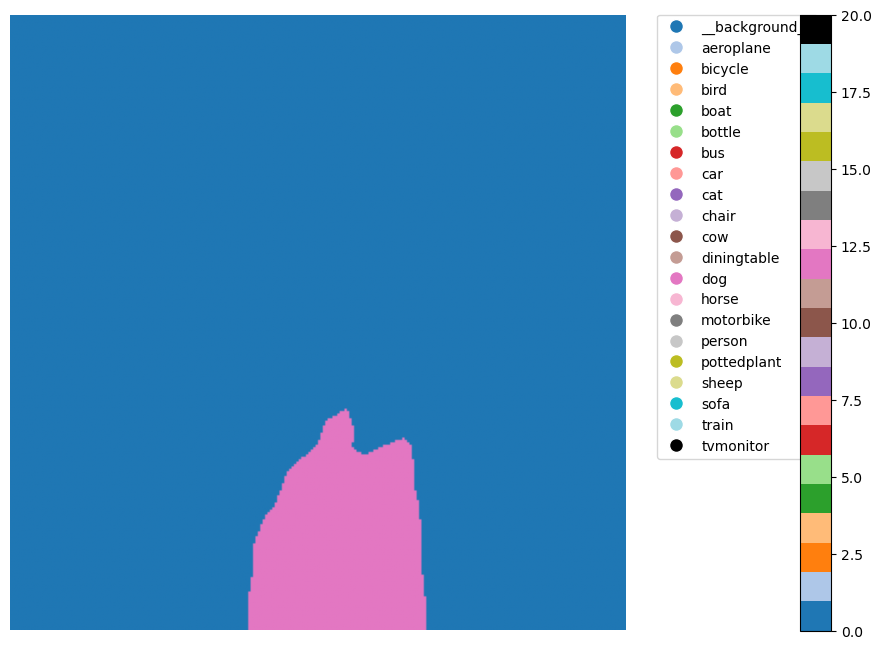

tensor([ 0, 12])


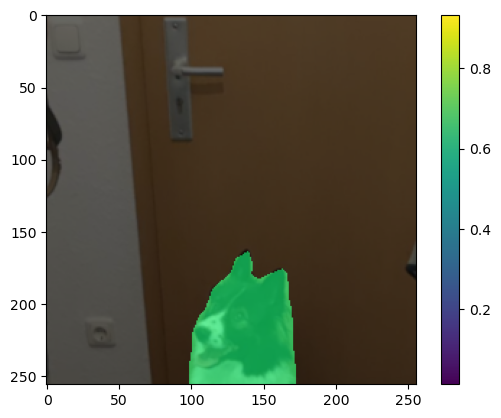

In [84]:
num_classes = normalized_masks.shape[1]
dog1_masks = normalized_masks[0]
class_dim = 0
dog1_all_classes_masks = dog1_masks.cpu().argmax(
    class_dim) == torch.arange(num_classes)[:, None, None]

print(f"dog1_masks shape = {dog1_masks.shape}, dtype = {dog1_masks.dtype}")
print(
    f"dog1_all_classes_masks = {dog1_all_classes_masks.shape}, dtype = {dog1_all_classes_masks.dtype}")

dog_with_all_masks = draw_segmentation_masks(
    img, masks=dog1_all_classes_masks, alpha=.6,).detach().cpu()

plt.figure(figsize=(45, 8))  # width, height in inches

from matplotlib.colors import ListedColormap

# 21 distinct colors (tab20 + black for the 21st class)
cmap = ListedColormap(plt.cm.tab20.colors +
                      ((0, 0, 0, 1),))  # RGBA for black

classes = ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus',
           'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike',
           'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']

for cls in classes:
    legend_handles = [plt.Line2D([0], [0], marker='o', color='w', label=cls,
                                 markerfacecolor=cmap(i), markersize=10) for i, cls in enumerate(classes)]
    plt.legend(handles=legend_handles, bbox_to_anchor=(
        1.05, 1), loc='upper left', borderaxespad=0.)
# plt.tight_layout()
plt.axis("off")


plt.imshow(normalized_masks[0].argmax(0).cpu(), cmap=cmap, vmin=0, vmax=20)
plt.axis("off")
plt.colorbar()
plt.show()
print(normalized_masks[0].argmax(0).cpu().unique())


plt.imshow(dog_with_all_masks.permute(1, 2, 0))
plt.colorbar()

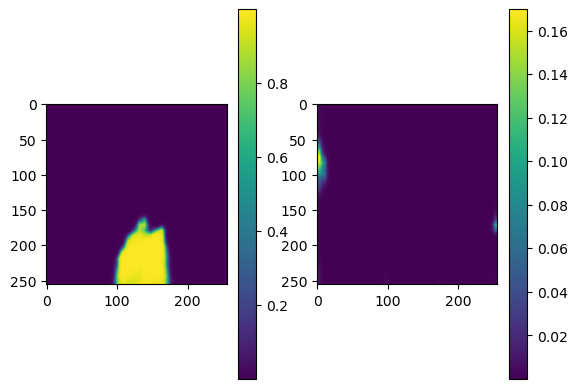

In [85]:
softmax = torch.softmax(output, dim=1)
plt.subplot(1, 2, 1)
plt.imshow(softmax[0, 12].cpu().numpy())
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(softmax[0, 15].cpu().numpy())
plt.colorbar()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0921803..3.0786111].


tensor(0.7471, device='cuda:0')


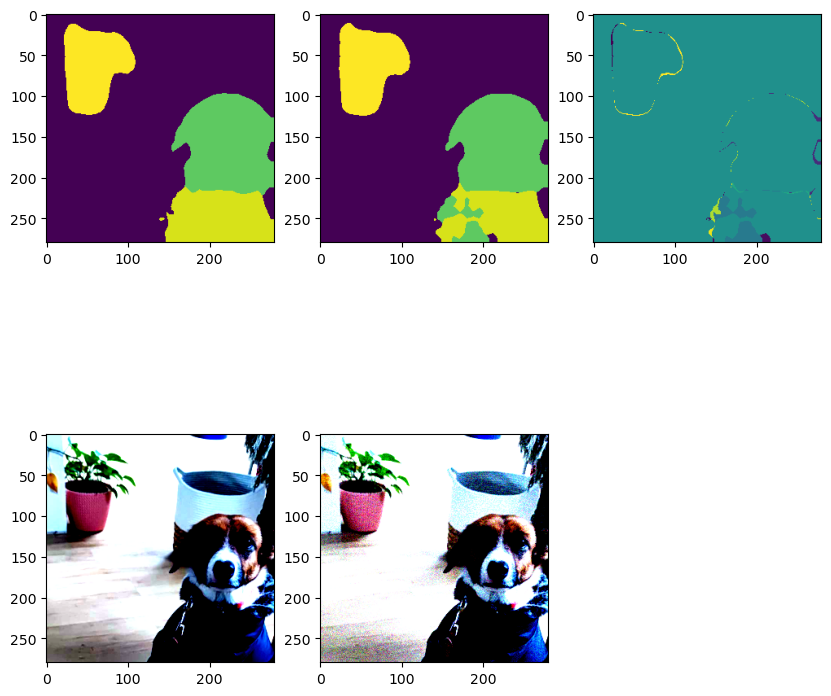

In [47]:
normalized_img = F.normalize(img, mean=(
    0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
output = model(normalized_img.unsqueeze(0))['out']

plt.figure(figsize=(10, 10))
plt.subplot(2, 3, 1)
plt.imshow(torch.argmax(output, 1).cpu()[0])
plt.subplot(2, 3, 4)
plt.imshow(normalized_img.cpu().permute(1, 2, 0))

noise = torch.rand(img.shape) * 0.1  # (2 * img.std().cpu()) + \
# (img.mean().cpu() - img.std().cpu())

noised_img = img + noise.to(img.device)


normalized_img_noised = F.normalize(noised_img, mean=(
    0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))

# gaussian_noise = GaussianNoise(
#     0, 0.1)

print(normalized_img_noised.mean())

# normalized_img_noised = gaussian_noise(normalized_img_noised)
out_noised = model(normalized_img_noised.unsqueeze(0))['out']

plt.subplot(2, 3, 2)
plt.imshow(torch.argmax(out_noised, 1).cpu()[0])

plt.subplot(2, 3, 5)
plt.imshow(normalized_img_noised.cpu().permute(1, 2, 0))

plt.subplot(2, 3, 3)
plt.imshow(torch.argmax(out_noised, 1).cpu()[
           0] - torch.argmax(output, 1).cpu()[0])

In [13]:
# wavelet_simplifier = simplification.WaveletSimplification(
#     lamb_soft_thresholding_compression=0.2, lamb_mul=0.15)

# seg_rep_pipe = simpRepair.SegmentRepairPipeline(
#     model=model,
#     img=img,
#     strategy=wavelet_simplifier,
#     lr_opt=0.01
# )

# out = seg_rep_pipe.do_simplification_procedure(
#     max_simp_it=10, max_it_opt=1000, inital_dice_weight=0.001, lambda_alpha=2.0, dice_er=0.001, lambda_tv=0.0001, patience=100, inital_alpha=1.0)

In [74]:
from skimage.color import rgb2hsv, hsv2rgb

hsv_image = rgb2hsv(img.permute(1, 2, 0).cpu().numpy())
value = hsv_image[:, :, 2]

coeffs = pywt.wavedec2(value, 'bior3.7', level=4)
print(len(coeffs))
print(coeffs[0].shape)
print("coeffs_0.size", coeffs[0].size)
print(len(coeffs[3]))
print(coeffs[4][0].shape)
print()
coeffs_arr, coeff_slices = pywt.coeffs_to_array(coeffs)

print("coeffs_arr", coeffs_arr.shape)
print(coeff_slices[1])
print(len(coeff_slices))

5
(30, 30)
coeffs_0.size 900
3
(135, 135)

coeffs_arr (315, 315)
{'ad': (slice(None, 30, None), slice(30, 60, None)), 'da': (slice(30, 60, None), slice(None, 30, None)), 'dd': (slice(30, 60, None), slice(30, 60, None))}
5


In [49]:
print(coeffs_arr.min())

-6.2771163


In [50]:
print(pywt.wavelist())

['bior1.1', 'bior1.3', 'bior1.5', 'bior2.2', 'bior2.4', 'bior2.6', 'bior2.8', 'bior3.1', 'bior3.3', 'bior3.5', 'bior3.7', 'bior3.9', 'bior4.4', 'bior5.5', 'bior6.8', 'cgau1', 'cgau2', 'cgau3', 'cgau4', 'cgau5', 'cgau6', 'cgau7', 'cgau8', 'cmor', 'coif1', 'coif2', 'coif3', 'coif4', 'coif5', 'coif6', 'coif7', 'coif8', 'coif9', 'coif10', 'coif11', 'coif12', 'coif13', 'coif14', 'coif15', 'coif16', 'coif17', 'db1', 'db2', 'db3', 'db4', 'db5', 'db6', 'db7', 'db8', 'db9', 'db10', 'db11', 'db12', 'db13', 'db14', 'db15', 'db16', 'db17', 'db18', 'db19', 'db20', 'db21', 'db22', 'db23', 'db24', 'db25', 'db26', 'db27', 'db28', 'db29', 'db30', 'db31', 'db32', 'db33', 'db34', 'db35', 'db36', 'db37', 'db38', 'dmey', 'fbsp', 'gaus1', 'gaus2', 'gaus3', 'gaus4', 'gaus5', 'gaus6', 'gaus7', 'gaus8', 'haar', 'mexh', 'morl', 'rbio1.1', 'rbio1.3', 'rbio1.5', 'rbio2.2', 'rbio2.4', 'rbio2.6', 'rbio2.8', 'rbio3.1', 'rbio3.3', 'rbio3.5', 'rbio3.7', 'rbio3.9', 'rbio4.4', 'rbio5.5', 'rbio6.8', 'shan', 'sym2', 'sym3

/home/amikliss/miniforge3/envs/segStrategiesEnv/lib/python3.11/site-packages/pywt/_multilevel.py:43: UserWarning: Level value of 5 is too high: all coefficients will experience boundary effects.
  warnings.warn(
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.038362566..1.0002129].


0
torch.Size([3, 256, 256])
Soft thresholding with lambda=0.1. For new lambda reinitalize the WaveletSimplification class
value min 0.055003434
value max 1.0002129
value min 0.055003434
value max 1.0002129
min tensor(0.0384, device='cuda:0')
max tensor(1.0002, device='cuda:0')


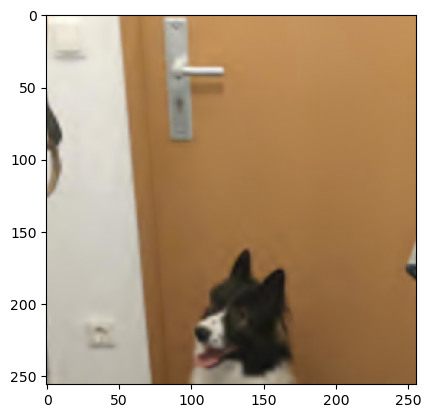

1
torch.Size([3, 256, 256])
Soft thresholding with lambda=0.2. For new lambda reinitalize the WaveletSimplification class
value min 0.04906089
value max 0.98122776
value min 0.04906089
value max 0.98122776
min tensor(0.0381, device='cuda:0')
max tensor(0.9812, device='cuda:0')


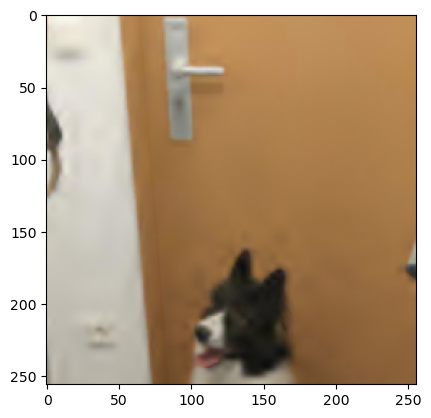

2
torch.Size([3, 256, 256])
Soft thresholding with lambda=0.4. For new lambda reinitalize the WaveletSimplification class
value min 0.044943944
value max 0.95166373
value min 0.044943944
value max 0.95166373
min tensor(0.0372, device='cuda:0')
max tensor(0.9517, device='cuda:0')


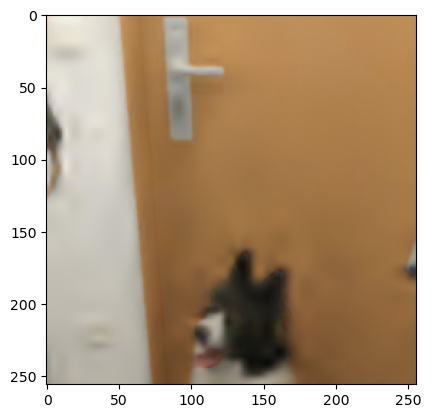

3
torch.Size([3, 256, 256])
Soft thresholding with lambda=0.8. For new lambda reinitalize the WaveletSimplification class
value min 0.029956656
value max 0.9058919
value min 0.029956656
value max 0.9058919
min tensor(0.0234, device='cuda:0')
max tensor(0.9059, device='cuda:0')


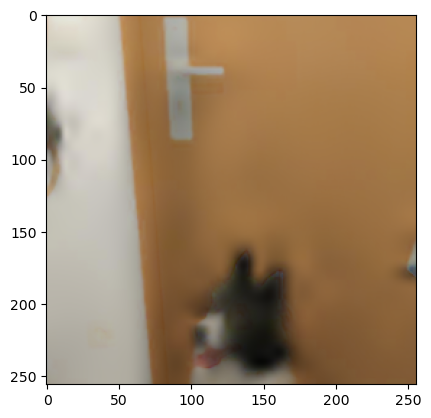

4
torch.Size([3, 256, 256])
Soft thresholding with lambda=1.6. For new lambda reinitalize the WaveletSimplification class
value min 0.018377468
value max 0.85530776
value min 0.018377468
value max 0.85530776
min tensor(0.0168, device='cuda:0')
max tensor(0.8553, device='cuda:0')


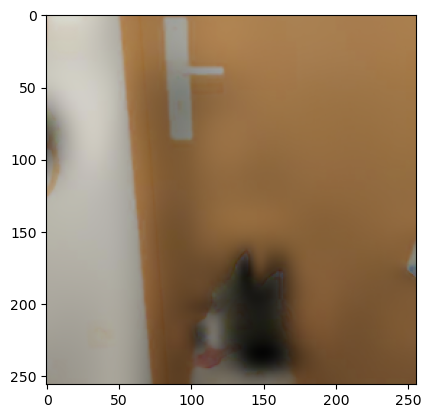

5
torch.Size([3, 256, 256])
Soft thresholding with lambda=3.2. For new lambda reinitalize the WaveletSimplification class
value min 0.043867867
value max 0.7444917
value min 0.043867867
value max 0.7444917
min tensor(0.0367, device='cuda:0')
max tensor(0.7445, device='cuda:0')


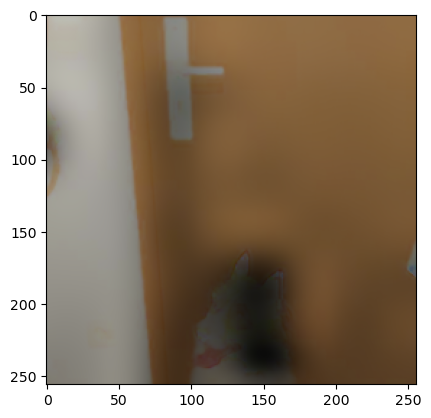

6
torch.Size([3, 256, 256])
Soft thresholding with lambda=6.4. For new lambda reinitalize the WaveletSimplification class
value min 0.01719226
value max 0.5379625
value min 0.01719226
value max 0.5379625
min tensor(0.0119, device='cuda:0')
max tensor(0.5380, device='cuda:0')


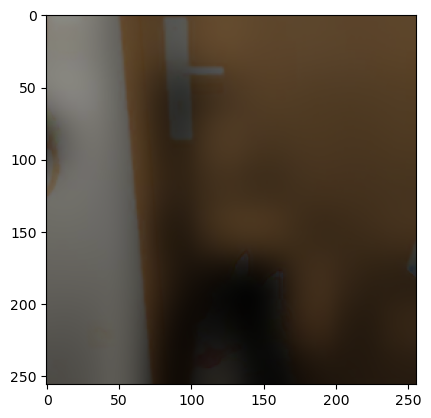

7
torch.Size([3, 256, 256])
Soft thresholding with lambda=12.8. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.13603728
value min 0.0
value max 0.13603728
min tensor(0., device='cuda:0')
max tensor(0.1360, device='cuda:0')


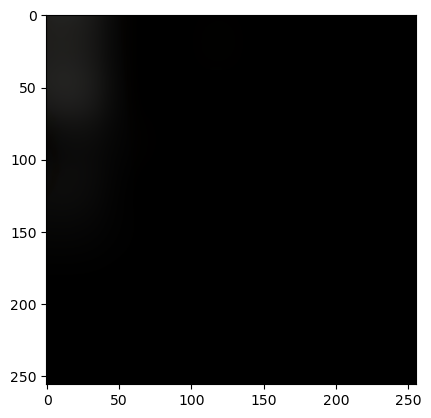

8
torch.Size([3, 256, 256])
Soft thresholding with lambda=25.6. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
value min 0.0
value max 0.0
min tensor(0., device='cuda:0')
max tensor(0., device='cuda:0')


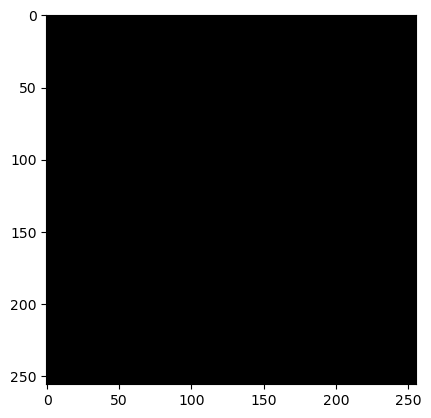

9
torch.Size([3, 256, 256])
Soft thresholding with lambda=51.2. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
value min 0.0
value max 0.0
min tensor(0., device='cuda:0')
max tensor(0., device='cuda:0')


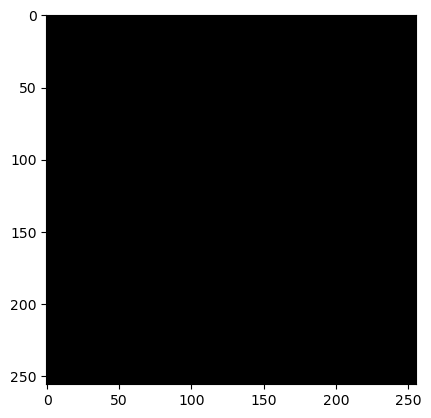

10
torch.Size([3, 256, 256])
Soft thresholding with lambda=102.4. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
value min 0.0
value max 0.0
min tensor(0., device='cuda:0')
max tensor(0., device='cuda:0')


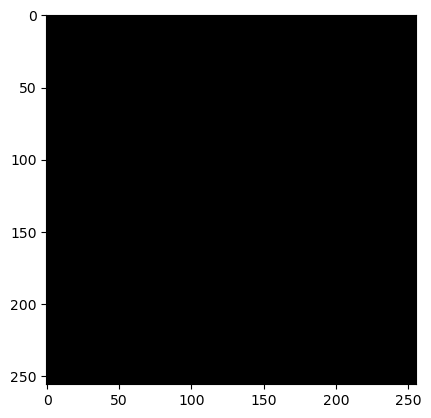

11
torch.Size([3, 256, 256])
Soft thresholding with lambda=204.8. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
value min 0.0
value max 0.0
min tensor(0., device='cuda:0')
max tensor(0., device='cuda:0')


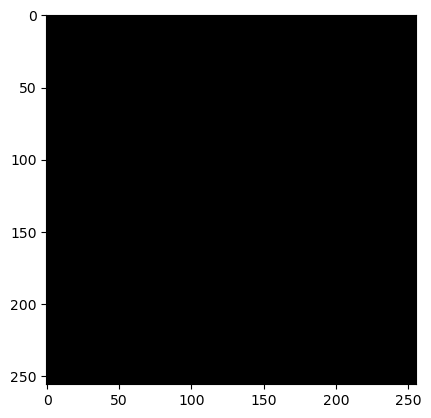

12
torch.Size([3, 256, 256])
Soft thresholding with lambda=409.6. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
value min 0.0
value max 0.0
min tensor(0., device='cuda:0')
max tensor(0., device='cuda:0')


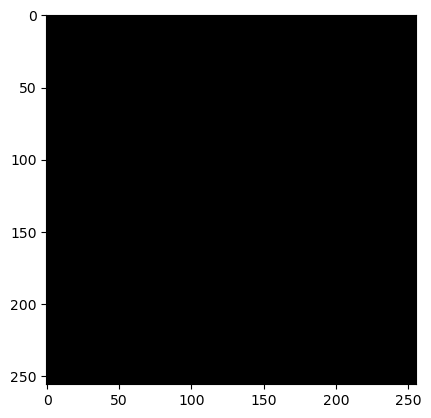

In [86]:
quantizer = simplification.ColorQuantizationSimplification(
    colors=80, lamb_mul=0.75)
# for i in range(20):
#     print(i)
#     simp = quantizer.simplify(img)
#     print(simp)
#     plt.imshow(torch.moveaxis(simp, 0, -1))
#     plt.show()

bilateral = simplification.Bilateral_Filter(
    sigma_color=0.01, inc_sigma_color=1.3, sigma_spatial=7)

blur = simplification.Gaussian_Blur(sigma=0.5, inc=1.5)

wavelet = simplification.WaveletSimplification(
    levels=5, lamb_soft_thresholding_compression=0.1, lamb_mul=2)
simp = img.clone()
for i in range(13):
    print(i)
    simp = wavelet.simplify(simp)
    print("min", simp.min())
    print("max", simp.max())
    plt.imshow(torch.moveaxis(simp.cpu(), 0, -1))
    plt.show()

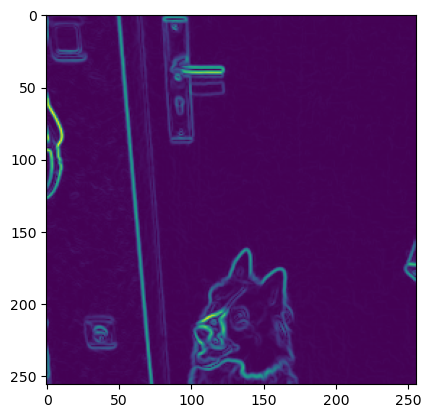

Simplification step 0
torch.Size([3, 256, 256])
Soft thresholding with lambda=0.1. For new lambda reinitalize the WaveletSimplification class
value min 0.055003434
value max 1.0002129
value min 0.055003434
value max 1.0002129
seg pres loss tensor(0.0267, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
no noise this time
seg_pres_loss tensor(0., device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0., device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
add random noise
seg_pres_loss tensor(0.0004, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-0.0002, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  at iteration

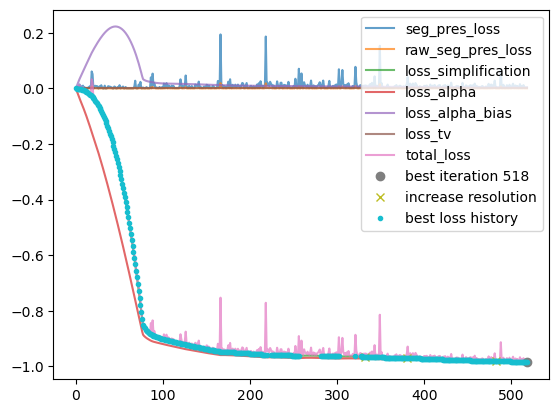

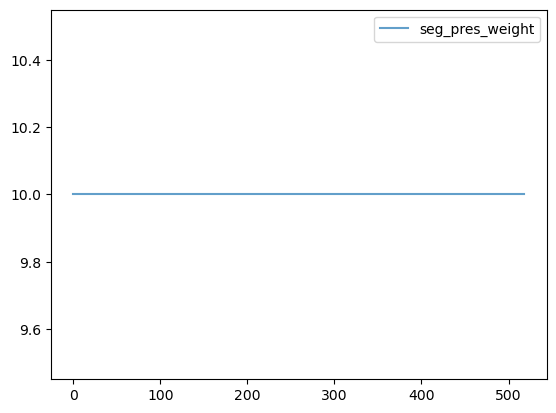

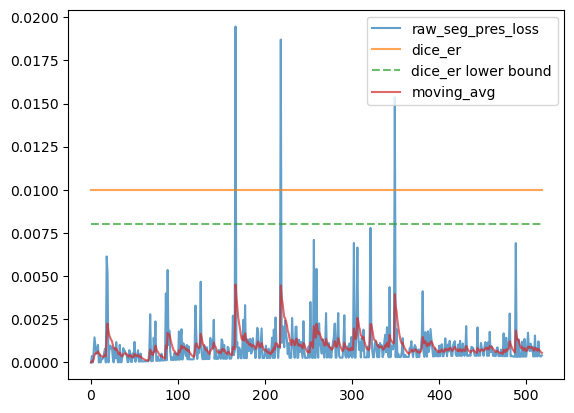

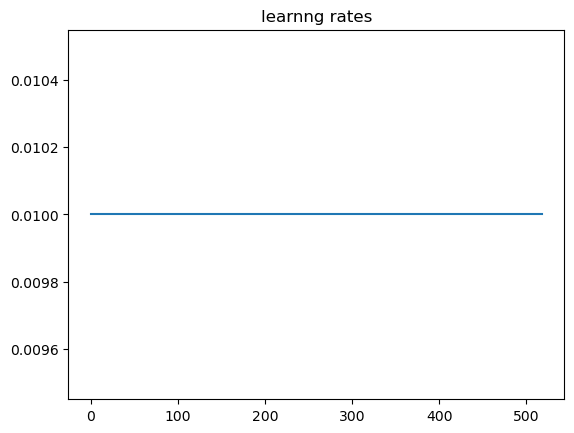

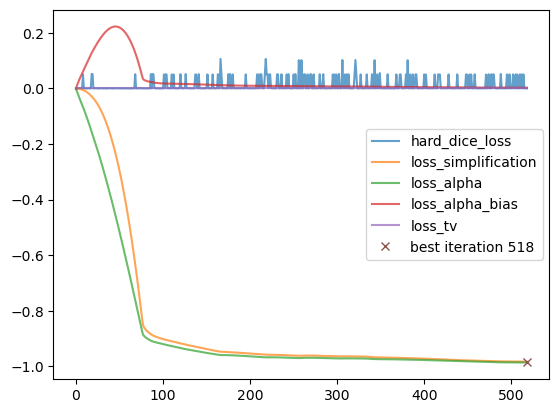

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.038362566..1.0002129].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.038362566..1.0002129].


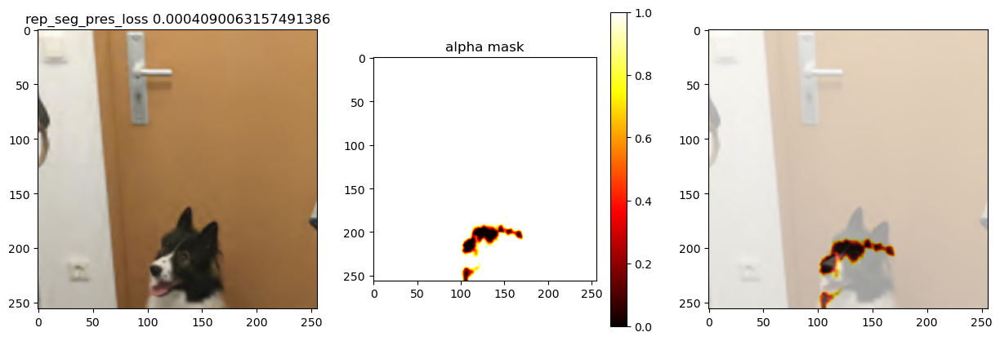

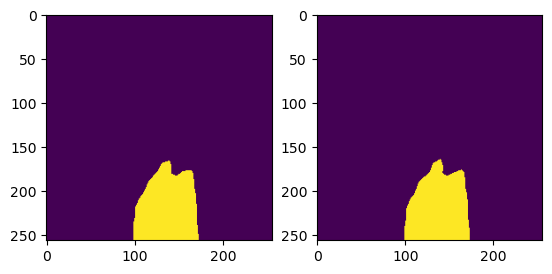

Simplification step 1
torch.Size([3, 256, 256])
Soft thresholding with lambda=0.2. For new lambda reinitalize the WaveletSimplification class
value min 0.048688777
value max 0.98122776
value min 0.048688777
value max 0.98122776
seg pres loss tensor(0.0765, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
add random noise
seg_pres_loss tensor(0.0013, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0013, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
add random noise
seg_pres_loss tensor(0.0003, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-0.0001, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  at i

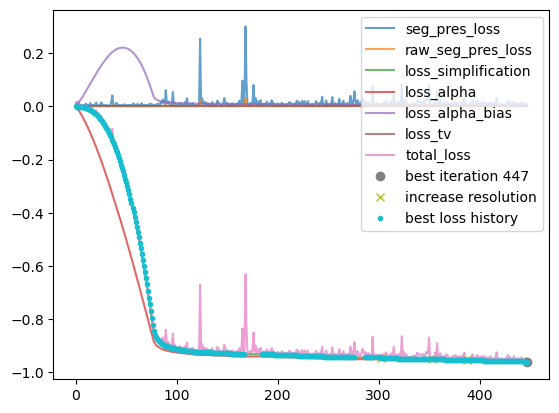

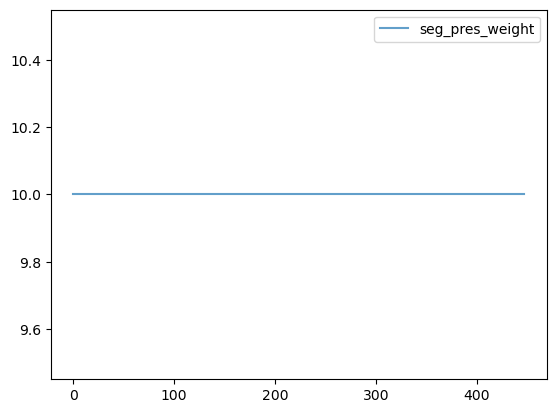

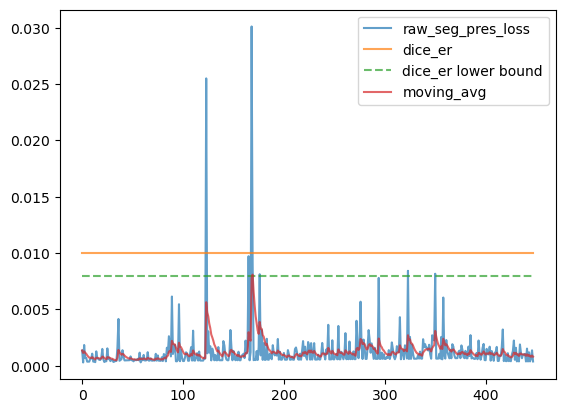

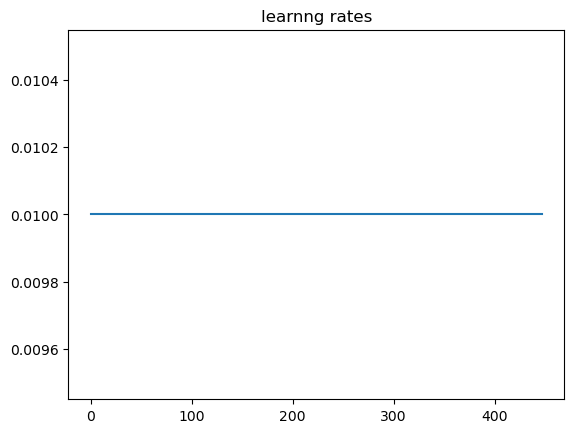

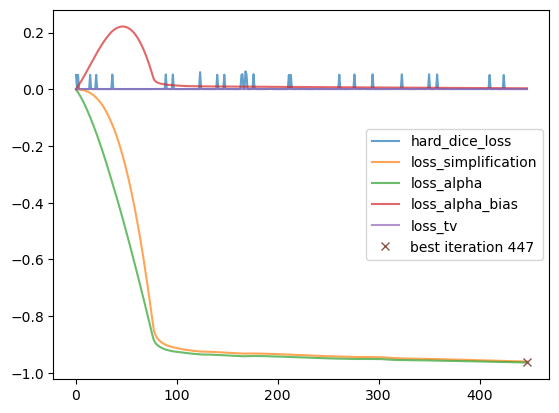

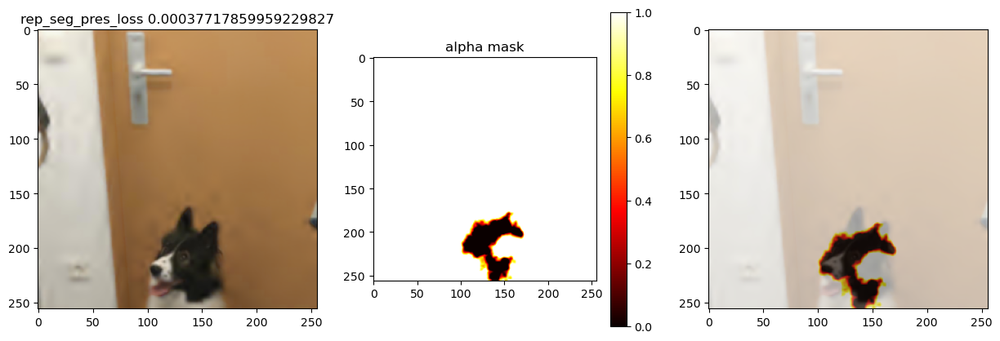

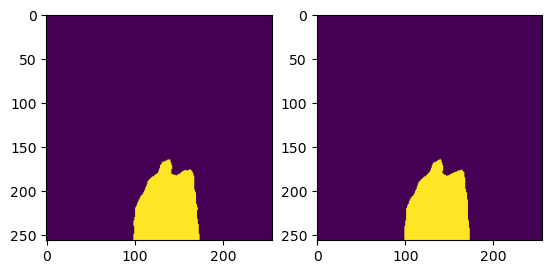

Simplification step 2
torch.Size([3, 256, 256])
Soft thresholding with lambda=0.4. For new lambda reinitalize the WaveletSimplification class
value min 0.056996647
value max 0.9516636
value min 0.056996647
value max 0.9516636
seg pres loss tensor(0.0520, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
add random noise
seg_pres_loss tensor(0.0006, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0006, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
no noise this time
seg_pres_loss tensor(0.0004, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-9.8419e-05, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  

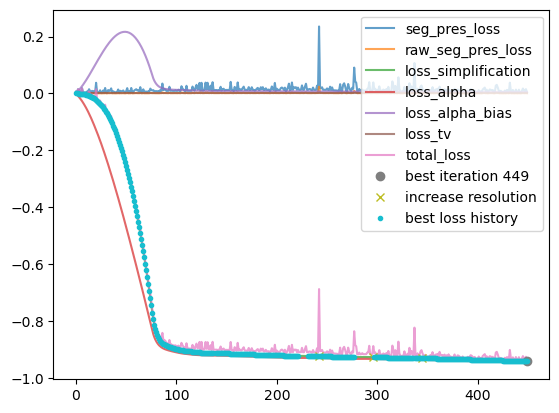

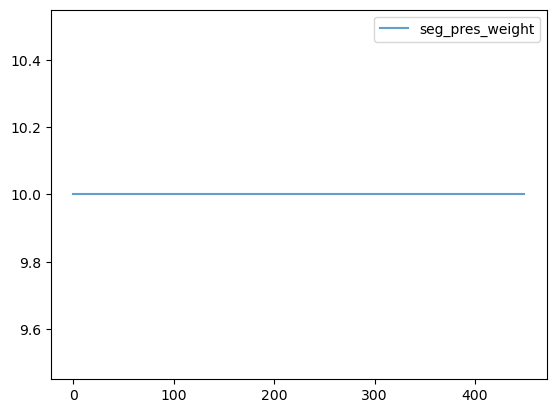

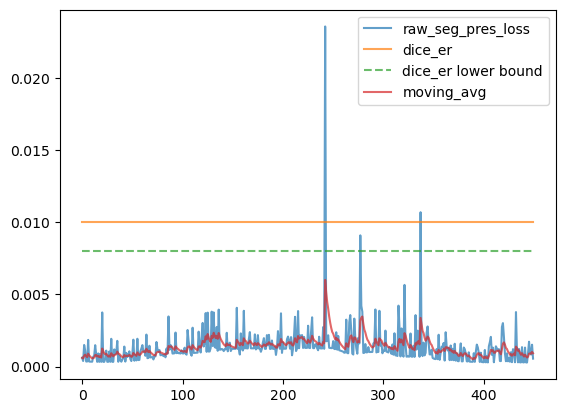

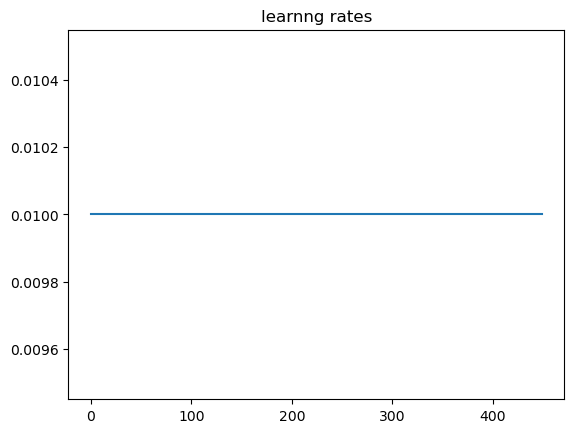

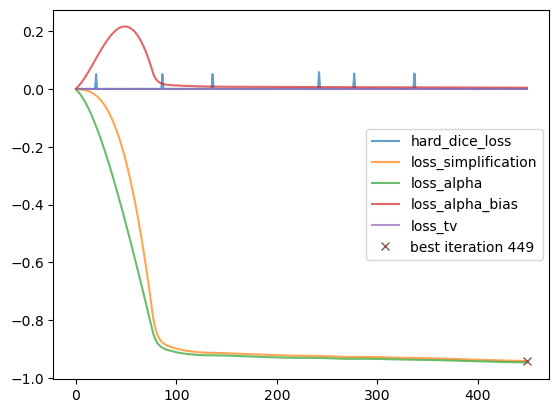

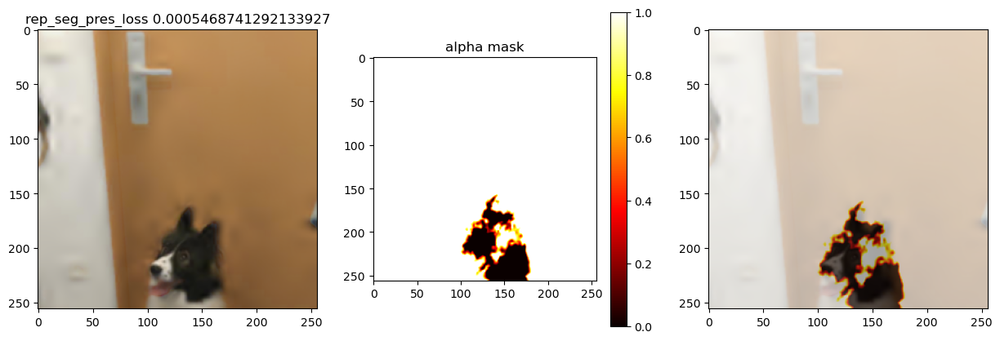

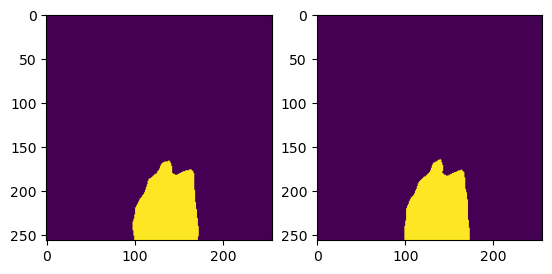

Simplification step 3
torch.Size([3, 256, 256])
Soft thresholding with lambda=0.8. For new lambda reinitalize the WaveletSimplification class
value min 0.04400766
value max 0.9058919
value min 0.04400766
value max 0.9058919
seg pres loss tensor(0.0782, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
no noise this time
seg_pres_loss tensor(0.0003, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0003, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
add random noise
seg_pres_loss tensor(0.0010, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-9.4361e-05, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  at

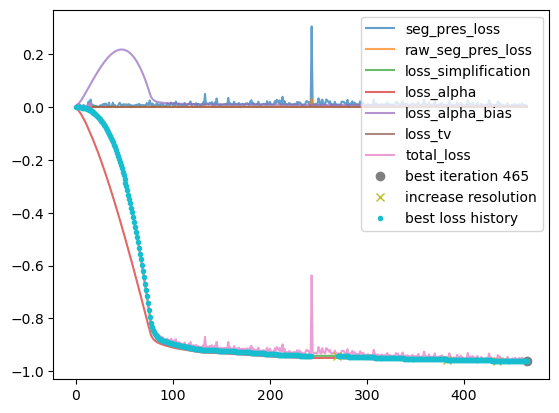

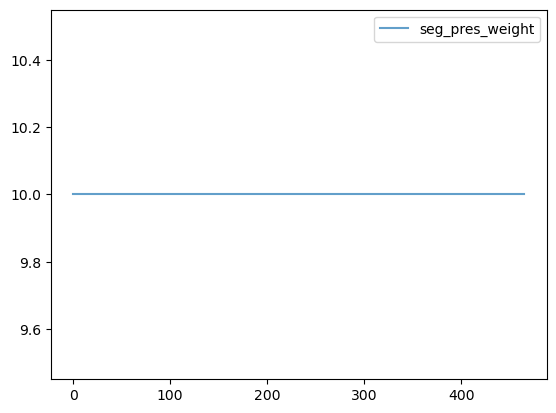

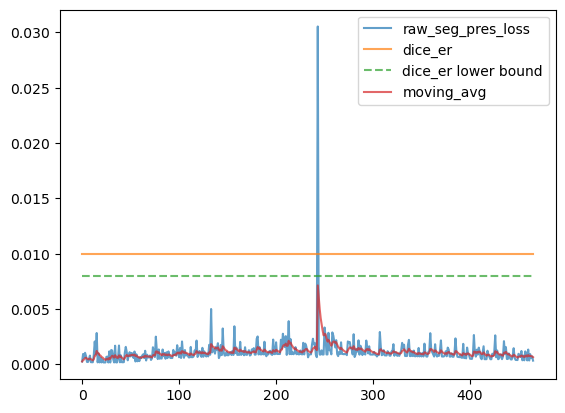

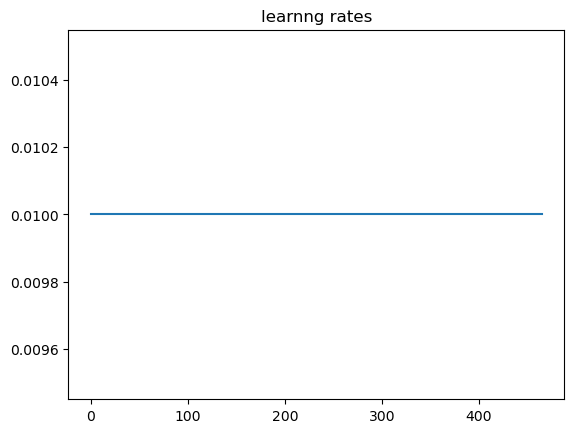

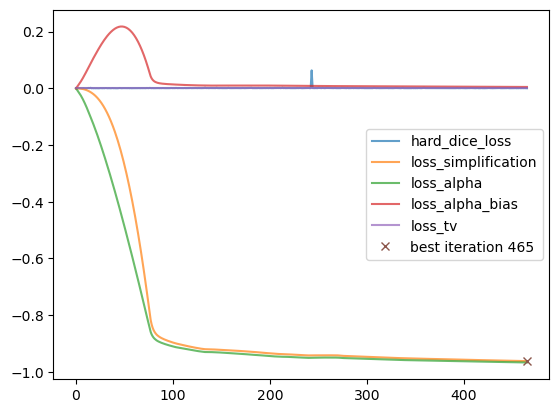

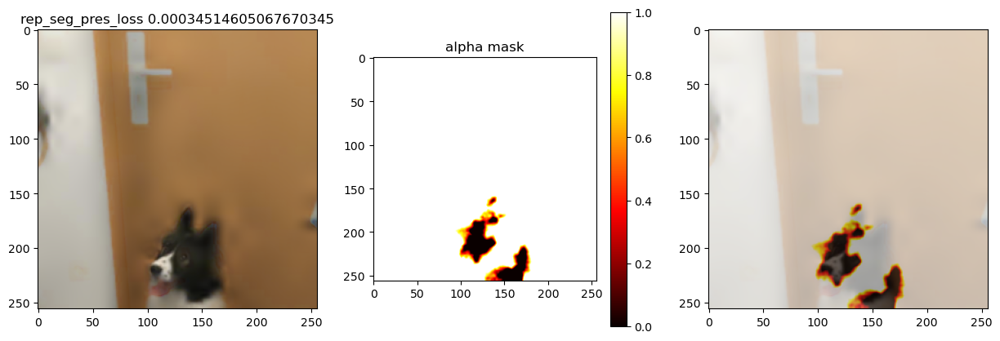

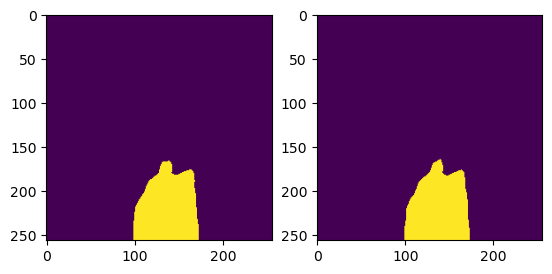

Simplification step 4
torch.Size([3, 256, 256])
Soft thresholding with lambda=1.6. For new lambda reinitalize the WaveletSimplification class
value min 0.025665883
value max 0.8553078
value min 0.025665883
value max 0.8553078
seg pres loss tensor(0.0795, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
no noise this time
seg_pres_loss tensor(0.0003, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0003, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
no noise this time
seg_pres_loss tensor(0.0003, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-7.6547e-05, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)

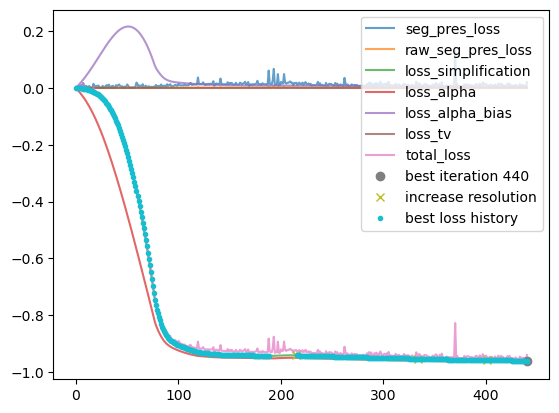

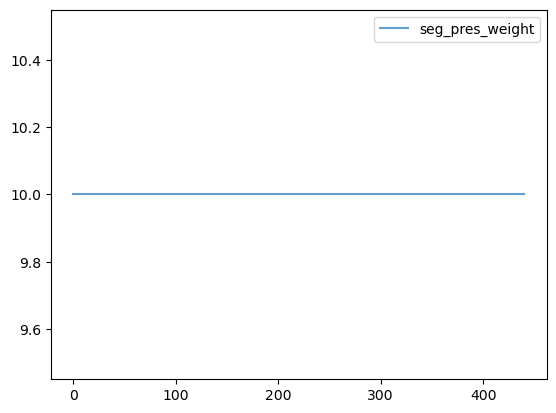

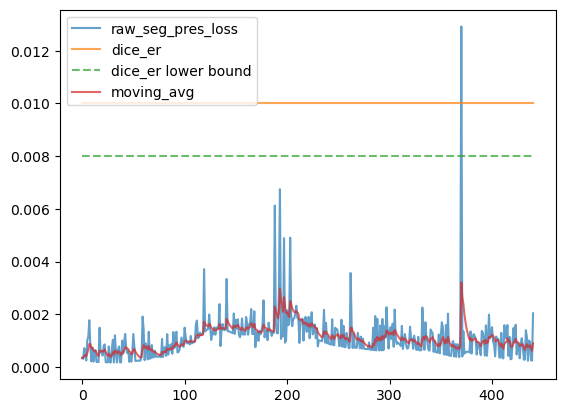

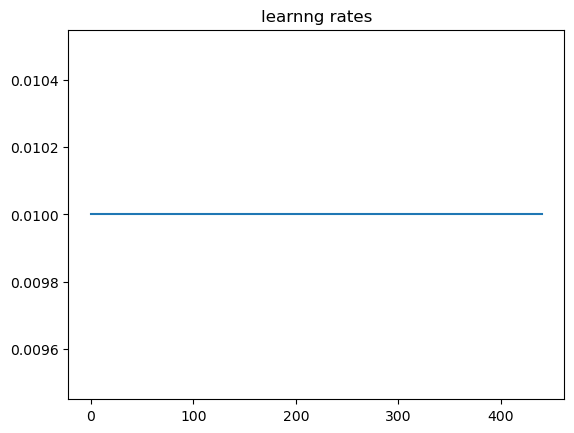

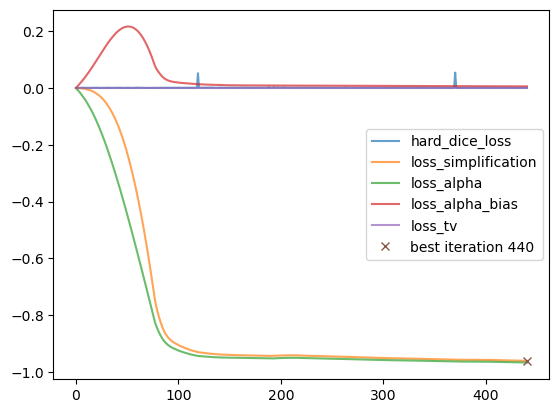

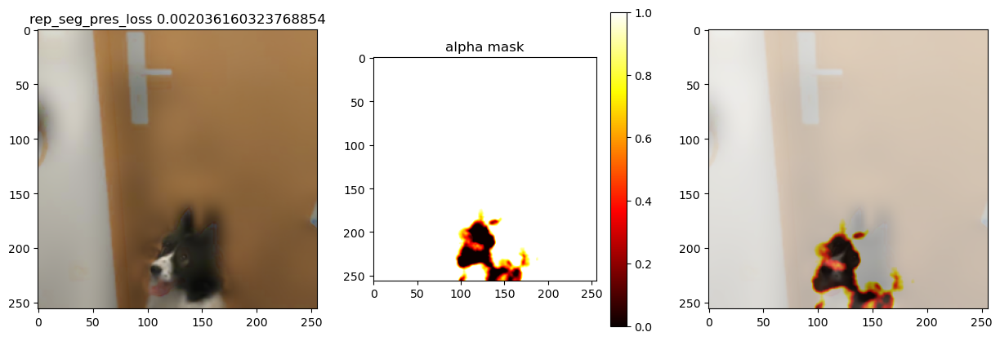

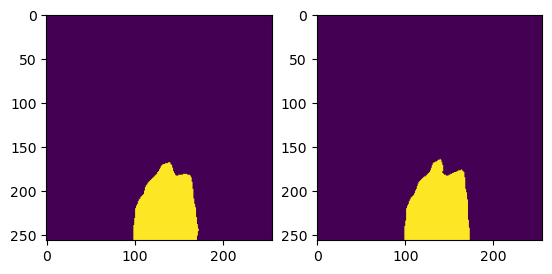

Simplification step 5
torch.Size([3, 256, 256])
Soft thresholding with lambda=3.2. For new lambda reinitalize the WaveletSimplification class
value min 0.013040235
value max 0.7444919
value min 0.013040235
value max 0.7444919
seg pres loss tensor(0.1034, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
add random noise
seg_pres_loss tensor(0.0010, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0010, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
add random noise
seg_pres_loss tensor(0.0010, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-5.3191e-05, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  at

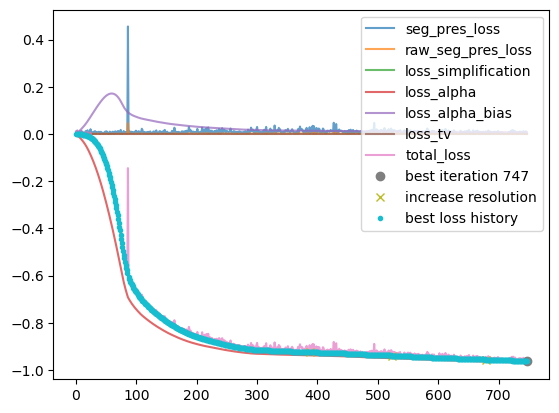

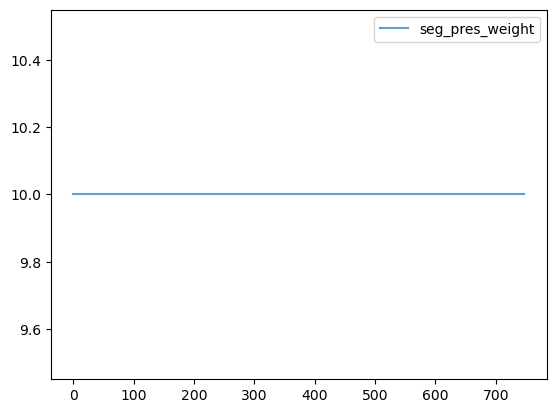

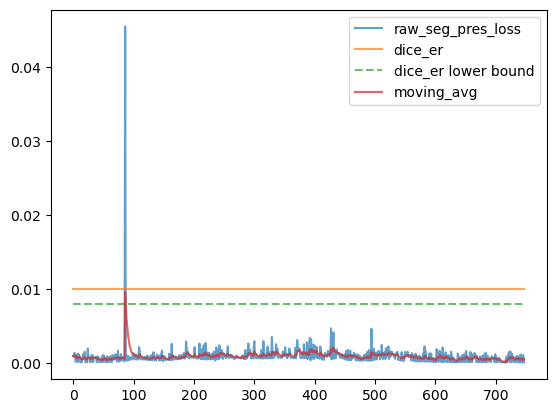

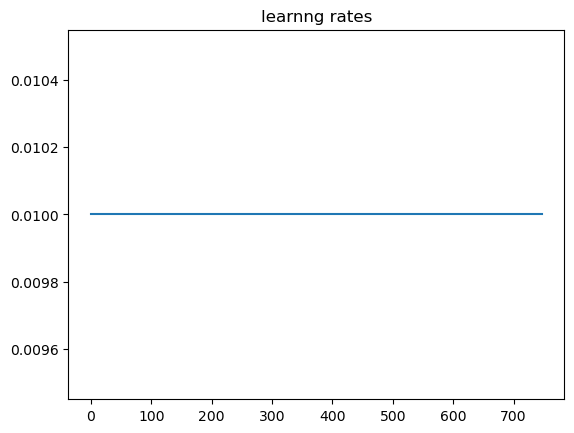

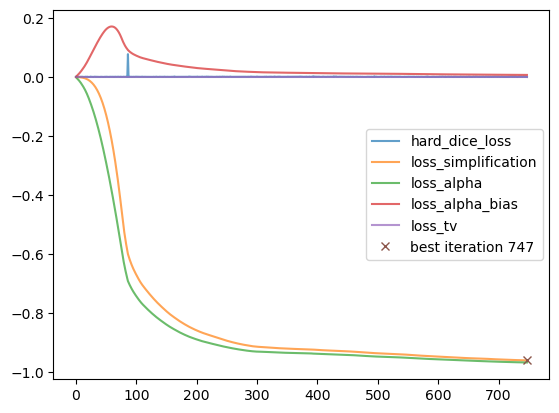

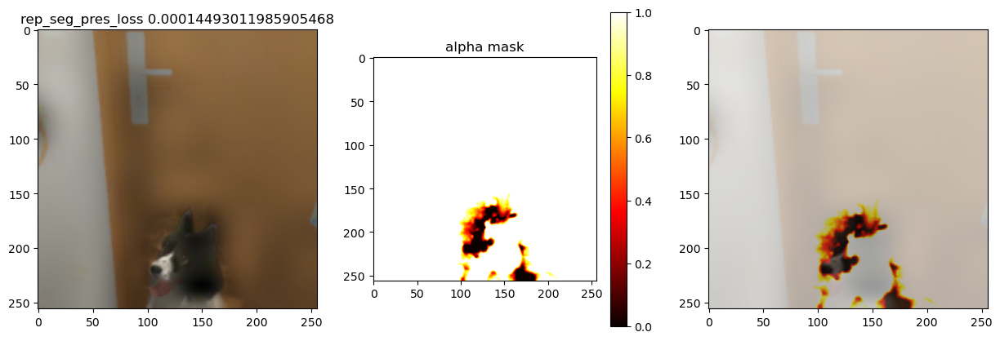

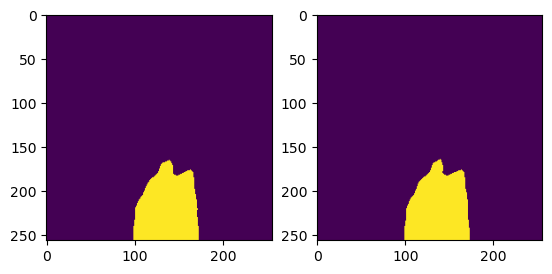

Simplification step 6
torch.Size([3, 256, 256])
Soft thresholding with lambda=6.4. For new lambda reinitalize the WaveletSimplification class
value min 0.048480198
value max 0.5379627
value min 0.048480198
value max 0.5379627
seg pres loss tensor(0.1035, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
add random noise
seg_pres_loss tensor(0.0008, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0008, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
add random noise
seg_pres_loss tensor(0.0008, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-6.1327e-05, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  at

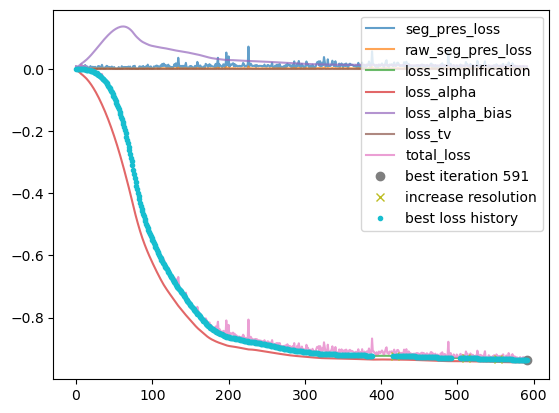

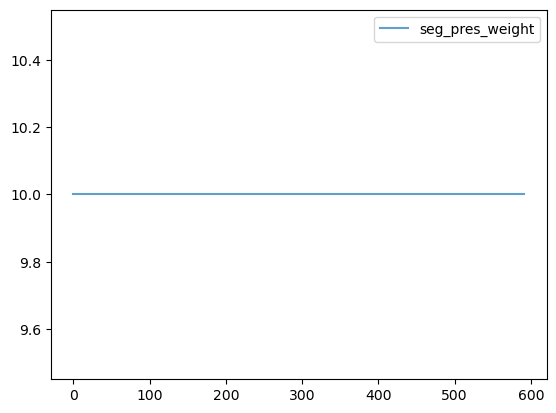

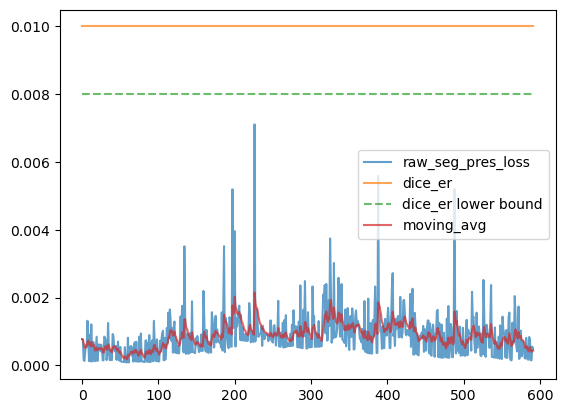

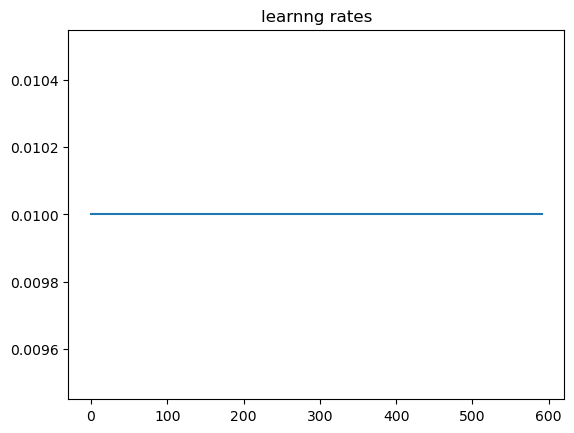

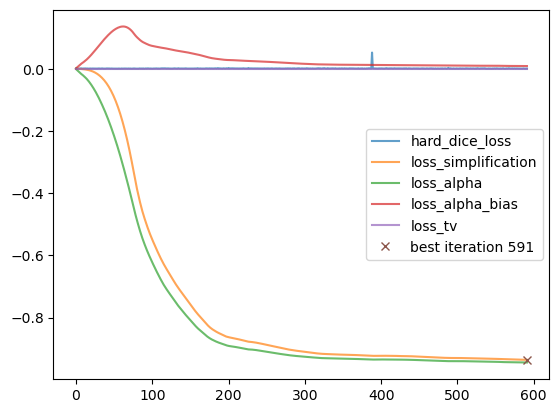

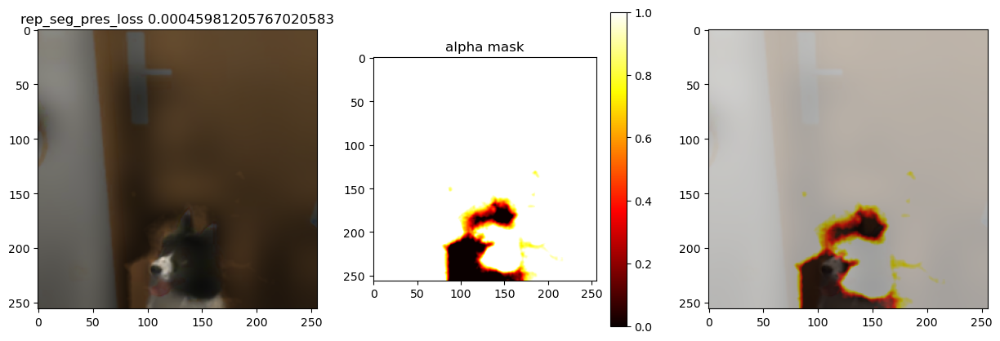

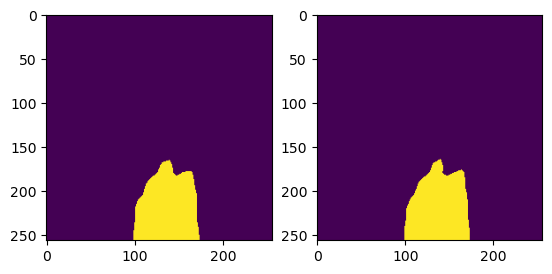

Simplification step 7
torch.Size([3, 256, 256])
Soft thresholding with lambda=12.8. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.13603352
value min 0.0
value max 0.13603352
seg pres loss tensor(0.1014, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
no noise this time
seg_pres_loss tensor(0.0001, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0001, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
no noise this time
seg_pres_loss tensor(0.0001, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-5.8369e-05, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  at iteratio

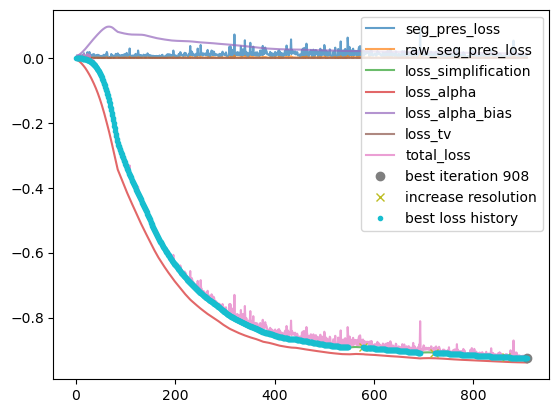

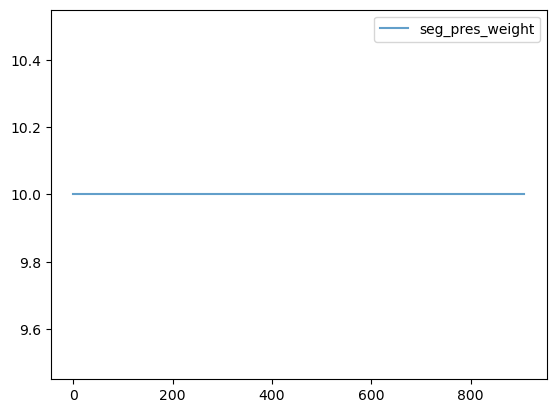

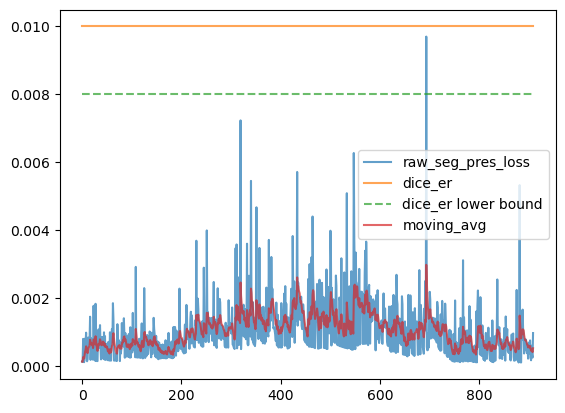

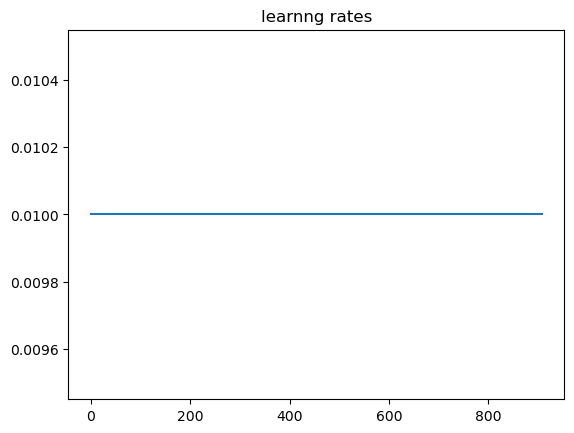

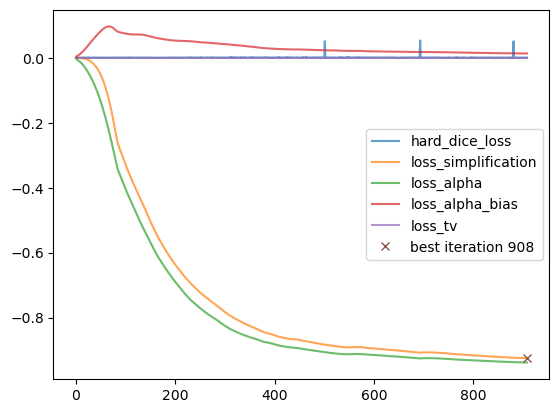

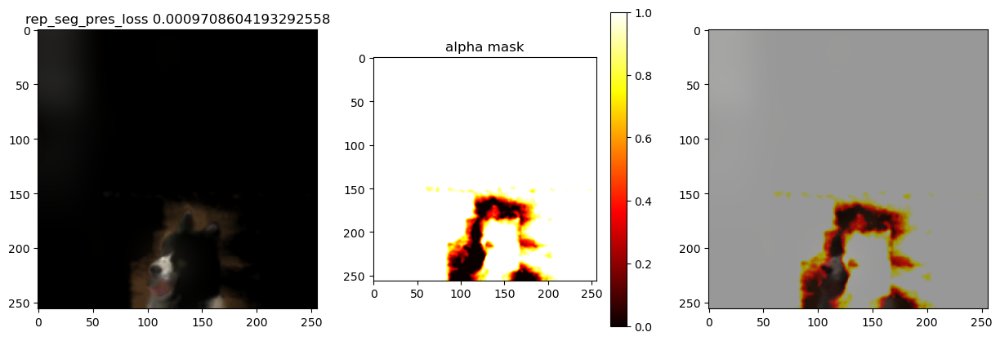

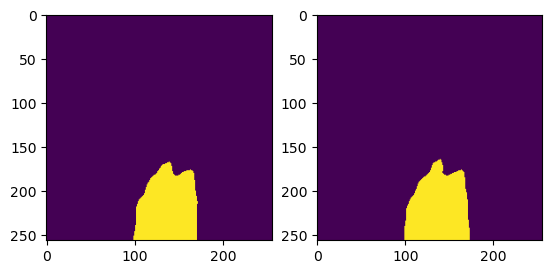

Simplification step 8
torch.Size([3, 256, 256])
Soft thresholding with lambda=25.6. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
value min 0.0
value max 0.0
seg pres loss tensor(0.1126, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
no noise this time
seg_pres_loss tensor(0.0002, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0002, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
add random noise
seg_pres_loss tensor(0.0006, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-0.0001, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  at iteration 0
iteration 1 seg_

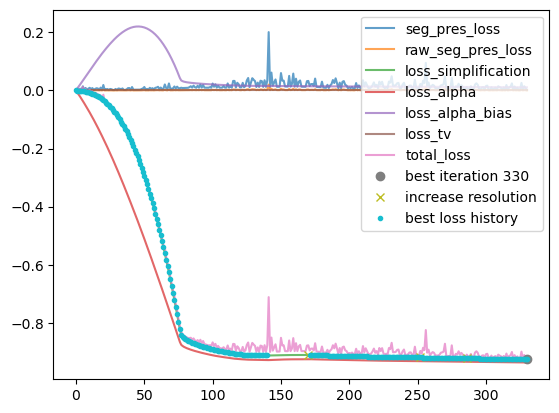

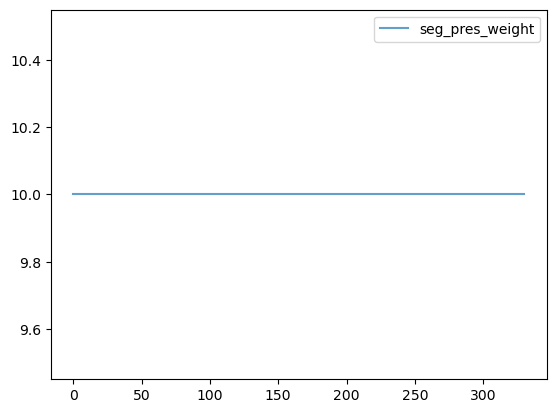

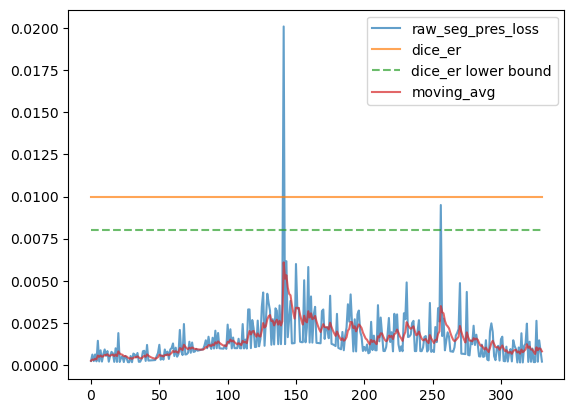

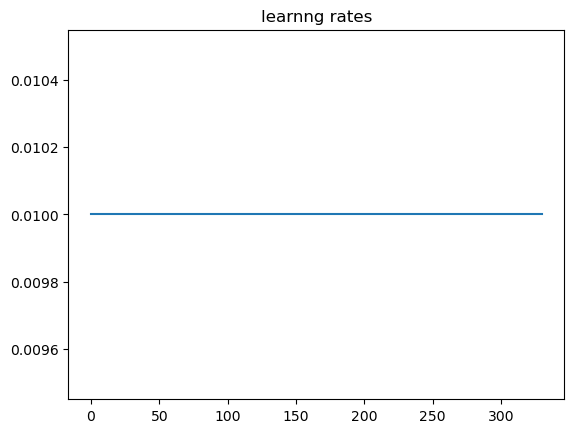

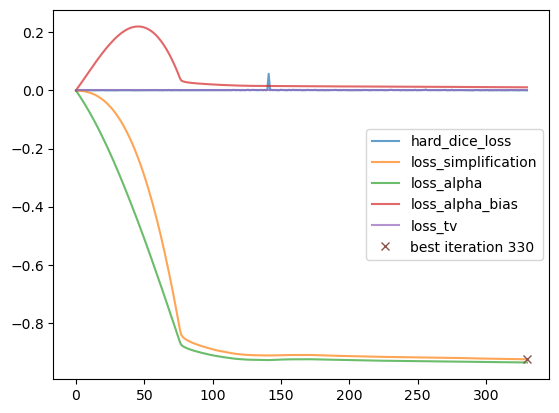

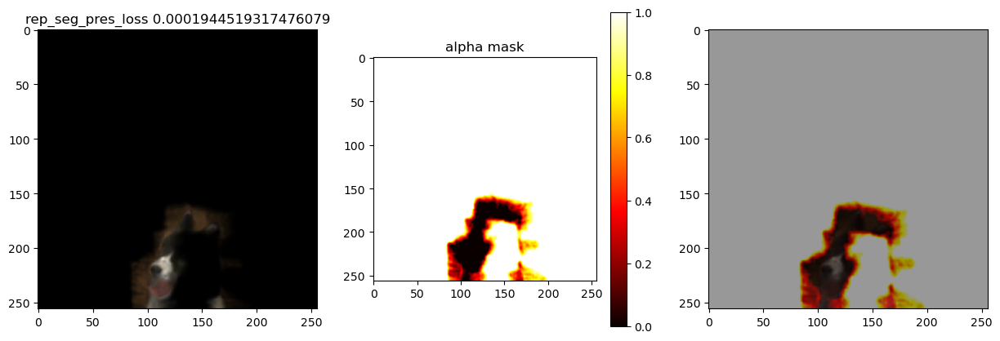

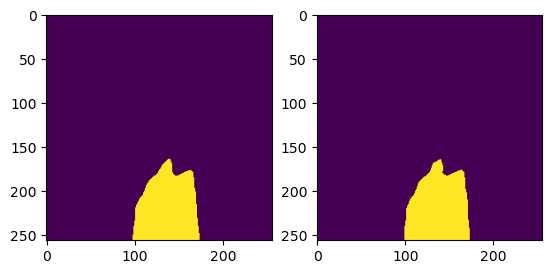

Simplification step 9
torch.Size([3, 256, 256])
Soft thresholding with lambda=51.2. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
value min 0.0
value max 0.0
seg pres loss tensor(0.1126, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
no noise this time
seg_pres_loss tensor(0.0002, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0002, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
add random noise
seg_pres_loss tensor(0.0012, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-0.0002, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  at iteration 0
iteration 1 seg_

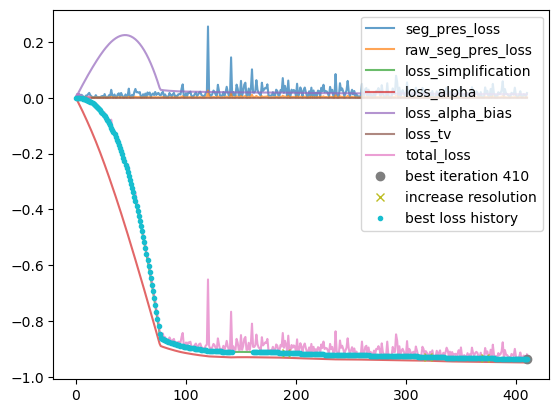

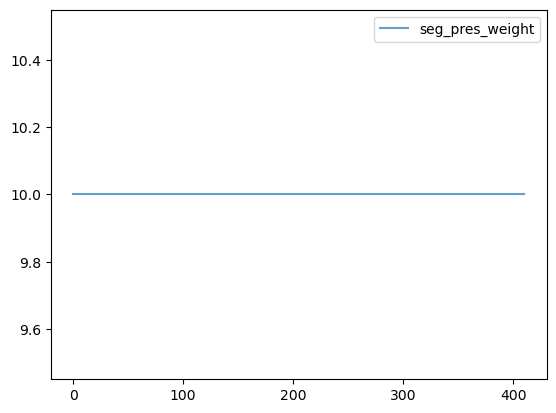

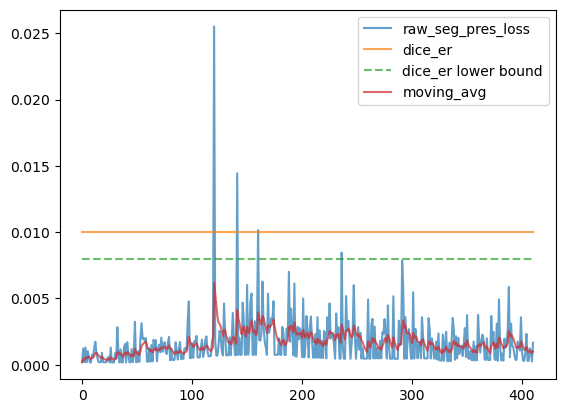

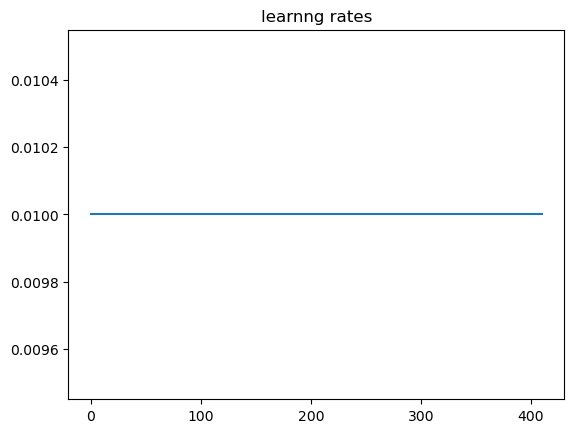

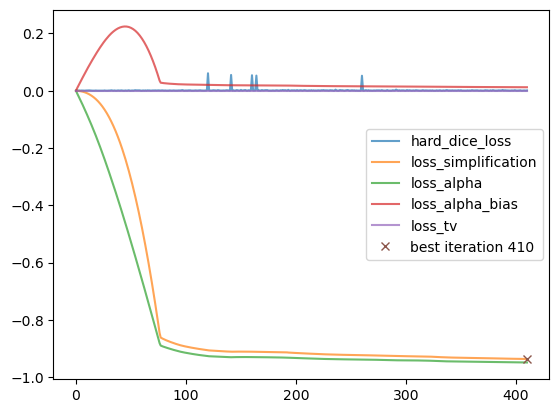

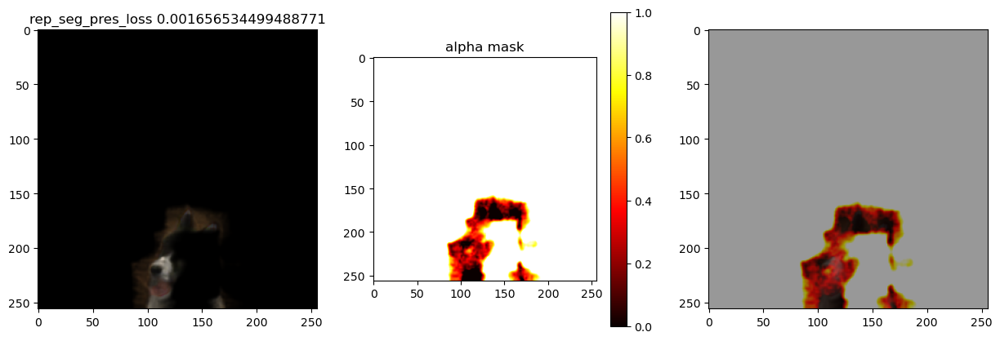

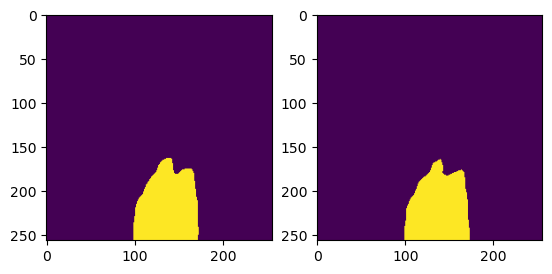

Simplification step 10
torch.Size([3, 256, 256])
Soft thresholding with lambda=102.4. For new lambda reinitalize the WaveletSimplification class
value min 0.0
value max 0.0
value min 0.0
value max 0.0
seg pres loss tensor(0.1126, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.01
add random noise
seg_pres_loss tensor(0.0027, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0027, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
no_improvement 0
inital lr 0.01
lr 0.01
add random noise
seg_pres_loss tensor(0.0010, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-0.0002, device='cuda:0', grad_fn=<AddBackward0>) best simp loss tensor(0., device='cuda:0', grad_fn=<AddBackward0>)  at iteration 0
iteration 1 seg_

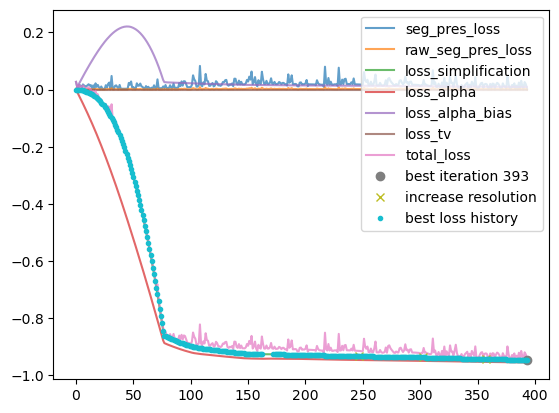

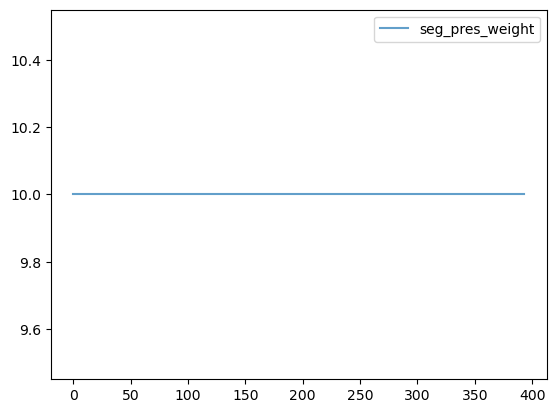

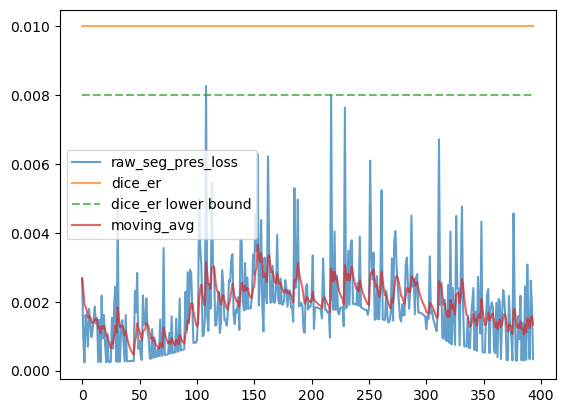

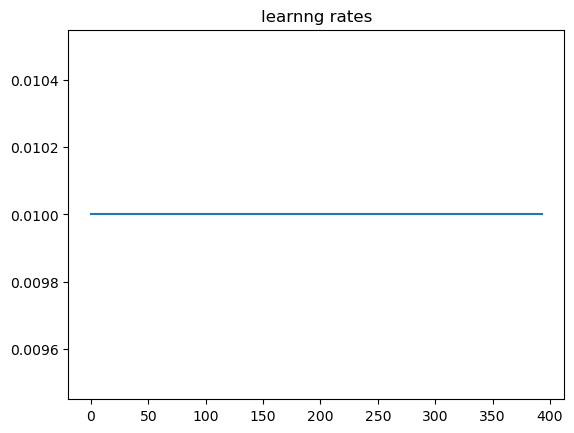

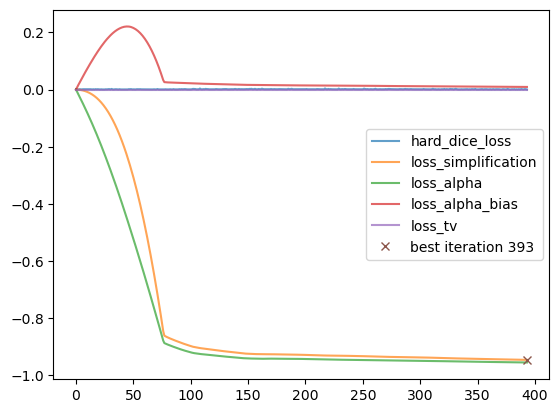

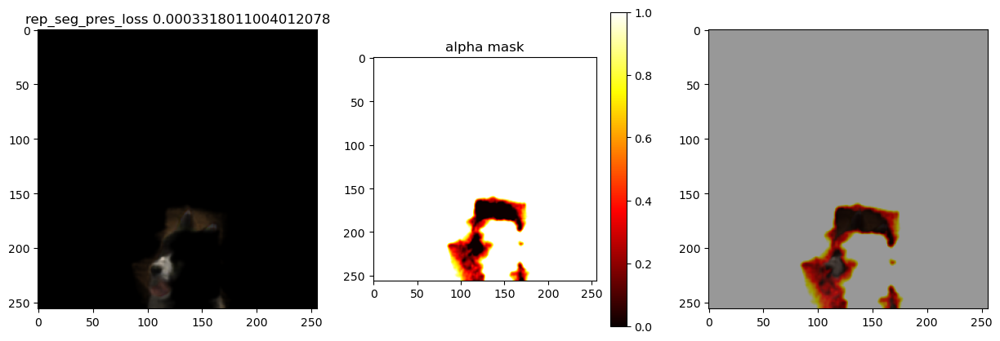

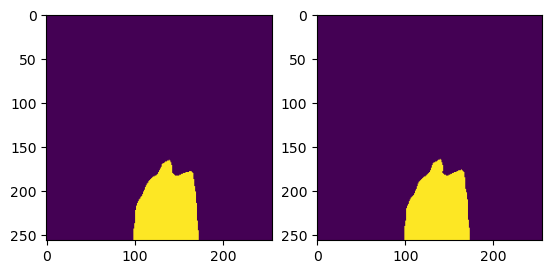

In [87]:
quantizer = simplification.ColorQuantizationSimplification(
    colors=80, lamb_mul=0.75)
blur = simplification.Gaussian_Blur(
    sigma=8, inc=1.2)
bilateral = simplification.Bilateral_Filter(
    sigma_color=0.01, inc_sigma_color=1.3, sigma_spatial=7)
wavelet = simplification.WaveletSimplification(
    levels=5, lamb_soft_thresholding_compression=0.1, lamb_mul=2)

uniform = simplification.Uniform_Image()

seg_rep_pipe = simpRepair.SegmentRepairPipeline(
    model=model,
    img=img,
    strategy=wavelet,
    lr_opt=.01,  # lr 0.1 sgd #adam2 0.001
    seg_pres_loss="margin"
)

out = seg_rep_pipe.do_simplification_procedure(
    max_simp_it=11, max_it_opt=2500, inital_dice_weight=10., lambda_alpha=1.0, dice_er=0.01, lambda_tv=0.0, lambda_magnitude_edge_weight=.8, patience=30, lambda_alpha_bias=.99, inital_alpha=0.)

# out = seg_rep_pipe.do_simplification_procedure(
#     max_simp_it=10, max_it_opt=1000, inital_dice_weight=0.001, lambda_alpha=2.0, dice_er=0.001, lambda_tv=0.0001, patience=100, inital_alpha=1.0)

In [42]:
for i in range(len(out["all_simp_imgs"])):
    print(i, torch.unique(out["all_simp_imgs"][i]))

0 tensor([0.0000e+00, 2.1161e-04, 1.3829e-03,  ..., 1.0223e+00, 1.0229e+00,
        1.0253e+00])
1 tensor([0.0000e+00, 2.7931e-04, 4.4734e-04,  ..., 1.0141e+00, 1.0175e+00,
        1.0176e+00])
2 tensor([0.0000e+00, 6.2167e-04, 1.0857e-03,  ..., 9.8440e-01, 9.8468e-01,
        9.8496e-01])
3 tensor([0.0000e+00, 4.7442e-04, 6.9007e-04,  ..., 9.5292e-01, 9.5307e-01,
        9.5323e-01])
4 tensor([0.0000e+00, 6.5713e-04, 7.0988e-04,  ..., 9.2827e-01, 9.2830e-01,
        9.2846e-01])
5 tensor([0.0000e+00, 5.0684e-05, 5.0797e-05,  ..., 8.5856e-01, 8.5857e-01,
        8.5862e-01])
6 tensor([0.0000e+00, 2.7299e-09, 2.8928e-09,  ..., 7.0549e-01, 7.0557e-01,
        7.0561e-01])
7 tensor([0.0000e+00, 2.5872e-08, 2.8224e-08,  ..., 5.0747e-01, 5.0780e-01,
        5.0791e-01])
8 tensor([0.0000e+00, 3.1151e-08, 3.5601e-08,  ..., 1.2868e-01, 1.2879e-01,
        1.2888e-01])
9 tensor([0.])
10 tensor([0.])
11 tensor([0.])


In [88]:
import imageio

final = out["all_rep_imgs"][-1].permute(1, 2, 0)

imageio.imwrite("emmi.tiff", final)

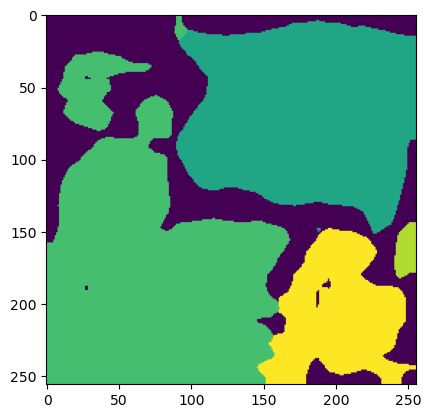

In [74]:
normalized_img = F.normalize(out["all_rep_imgs"][-1], mean=(
    0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)).to(device)
output = model(normalized_img.unsqueeze(0))['out']

plt.imshow(output.argmax(1).cpu().numpy()[0])

tensor(0.6766)
tensor(0.6765)
seg pres loss 0.0016881704796105623
seg pres loss 0.0002903403656091541


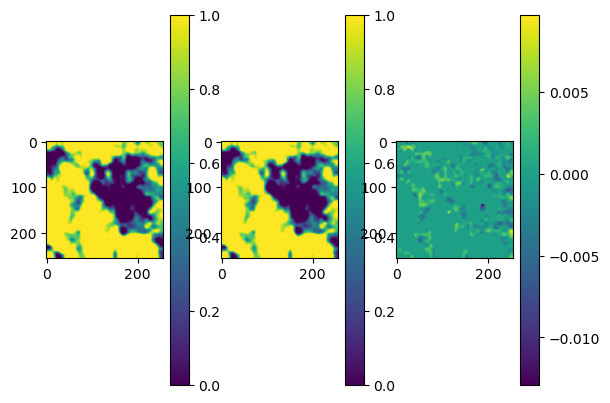

In [32]:
a = out["all_alpha_history"][6][451]
b = out["all_alpha_history"][6][452]
plt.subplot(1, 3, 1)
plt.imshow(a)
plt.colorbar()
plt.subplot(1, 3, 2)
plt.imshow(b)
plt.colorbar()
plt.subplot(1, 3, 3)
plt.imshow(a - b)
plt.colorbar()
print(a.mean())
print(b.mean())


l1 = out["all_log_losses"][6]["raw_seg_pres_loss"][451]
print("seg pres loss", l1)
l2 = out["all_log_losses"][6]["raw_seg_pres_loss"][452]
print("seg pres loss", l2)

2500
tensor([[1., 1., 1.,  ..., 0., 0., 0.],
        [1., 1., 1.,  ..., 0., 0., 0.],
        [1., 1., 1.,  ..., 0., 0., 0.],
        ...,
        [1., 1., 1.,  ..., 0., 0., 0.],
        [1., 1., 1.,  ..., 0., 0., 0.],
        [1., 1., 1.,  ..., 0., 0., 0.]])


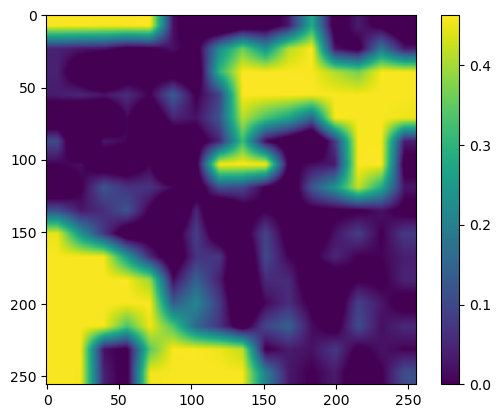

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0166097].


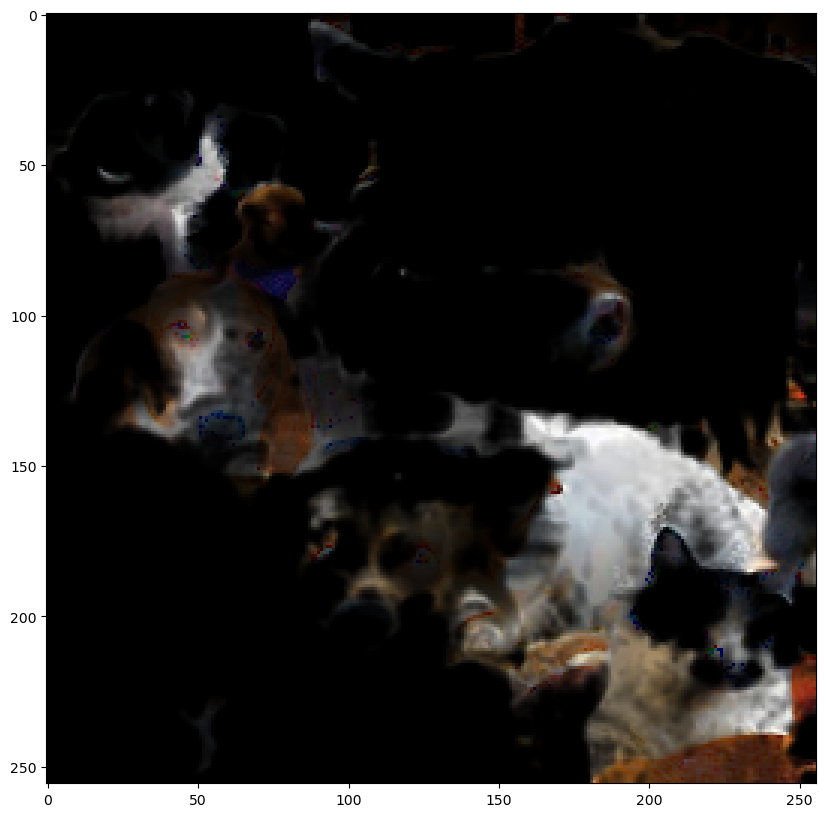

torch.Size([256, 256])


Text(0.5, 1.0, 'summed and binarized')

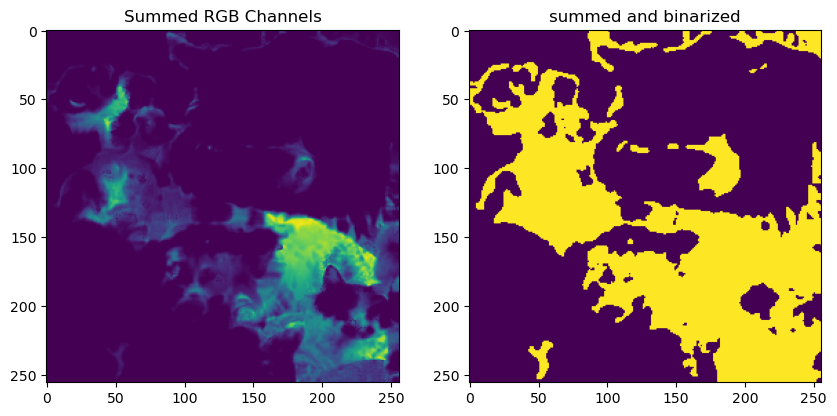

In [75]:
print(len(out["all_alpha_history"][5]))
print(out["all_alpha_history"][-1][-1])

plt.imshow(out["all_alpha_history"][-1][40])
plt.colorbar()
plt.show()

plt.figure(figsize=(10, 10))
plt.imshow(out["all_rep_imgs"][-1].permute(1, 2, 0))
plt.show()

# where not zero

plt.figure(figsize=(10, 10))
s = torch.sum(out["all_rep_imgs"][-1].permute(1, 2, 0), dim=(2))
print(s.shape)
plt.subplot(1, 2, 1)
plt.imshow(s)
plt.title("Summed RGB Channels")
plt.subplot(1, 2, 2)
plt.imshow(torch.where(s > 0, 1, 0))
plt.title("summed and binarized")

In [ ]:
import visualization_utils
visualization_utils.visualizeSimplification(
    out, name="collage.mp4", save=False)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0166097].


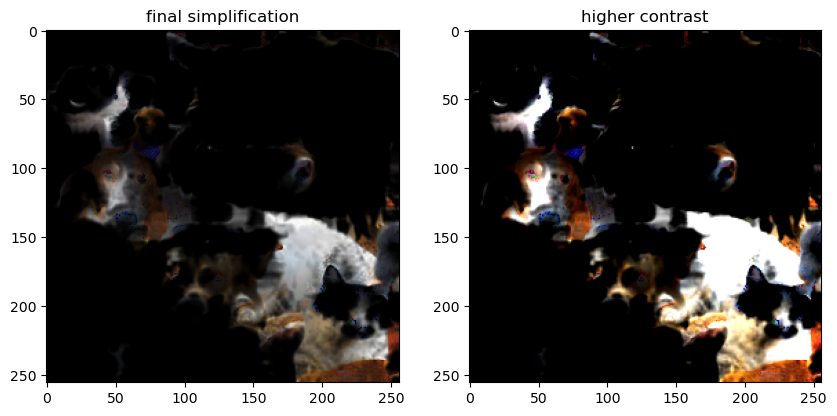

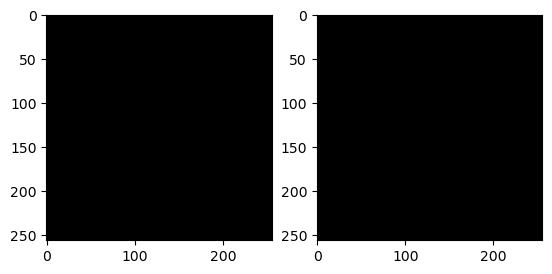

tensor([0.])


In [77]:
from torchvision.transforms.functional import adjust_contrast

plt.figure(figsize=(10, 20))
plt.subplot(1, 2, 1)
plt.imshow(out["all_rep_imgs"][-1].permute(1, 2, 0))
plt.title("final simplification")
plt.subplot(1, 2, 2)
plt.imshow(adjust_contrast(out["all_rep_imgs"][-1], 2.5).permute(1, 2, 0))
plt.title("higher contrast")
plt.show()

plt.subplot(1, 2, 1)
plt.imshow(out["all_simp_imgs"][-2].permute(1, 2, 0))
plt.subplot(1, 2, 2)
plt.imshow(adjust_contrast(out["all_simp_imgs"][-2], 20).permute(1, 2, 0))
plt.show()

print(torch.unique(out["all_simp_imgs"][-1]))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.028266937..1.0189375].


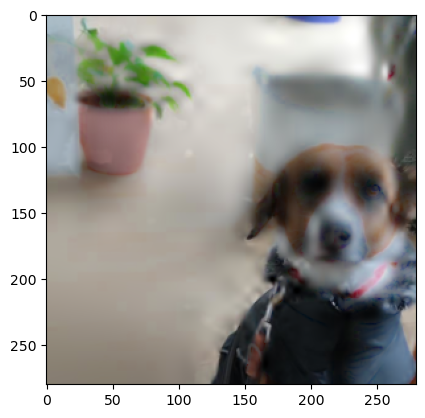

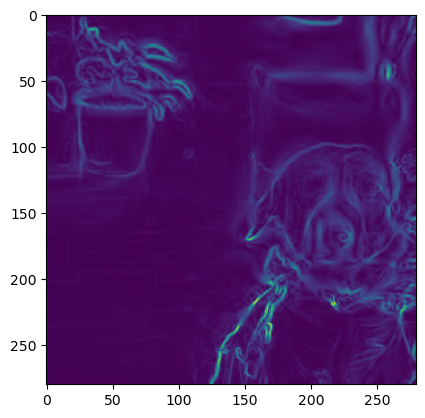

Simplification step 0
torch.Size([3, 280, 280])
Soft thresholding with lambda=9.2. For new lambda reinitalize the WaveletSimplification class
seg pres loss tensor(0.1151, device='cuda:0')
do repairing
Using optimizer Adam with learning rate 0.1
seg_pres_loss tensor(0.0020, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 0 loss simplification tensor(0., device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 0 seg_pres_loss tensor(0.0020, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
seg_pres_loss 0.0020041458774358034 is not good enough, not saving best loss
no_improvement 0
inital lr 0.1
lr 0.1
seg_pres_loss tensor(0.0020, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 1 loss simplification tensor(-0.0054, device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 1 seg_pres_loss tensor(0.0020, device='cuda:0', grad_fn=<MeanBackward0

/home/amikliss/miniforge3/envs/segStrategiesEnv/lib/python3.11/site-packages/pywt/_multilevel.py:43: UserWarning: Level value of 5 is too high: all coefficients will experience boundary effects.
  warnings.warn(


tensor(0.0012, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
seg_pres_loss 0.0011965708108618855 is not good enough, not saving best loss
no_improvement 0
inital lr 0.1
lr 0.1
seg_pres_loss tensor(0.0010, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 3 loss simplification tensor(-0.0218, device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 3 seg_pres_loss tensor(0.0010, device='cuda:0', grad_fn=<MeanBackward0>)
diff best simp and current simp tensor(-inf, device='cuda:0', grad_fn=<SubBackward0>)
seg_pres_loss 0.0009751564939506352 is not good enough, not saving best loss
no_improvement 0
inital lr 0.1
lr 0.1
seg_pres_loss tensor(0.0022, device='cuda:0', grad_fn=<MeanBackward0>)
iteration 4 loss simplification tensor(-0.0334, device='cuda:0', grad_fn=<AddBackward0>) best simp loss inf  at iteration None
iteration 4 seg_pres_loss tensor(0.0022, device='cuda:0', grad

KeyboardInterrupt: 

In [63]:
plt.imshow(out["all_rep_imgs"][2].cpu().permute(1, 2, 0))
plt.show()


wavelet = simplification.WaveletSimplification(
    levels=5, lamb_soft_thresholding_compression=9.2, lamb_mul=1.5)

uniform = simplification.Uniform_Image()

seg_rep_pipe = simpRepair.SegmentRepairPipeline(
    model=model,
    img=out["all_rep_imgs"][2],
    strategy=wavelet,
    lr_opt=.1,  # lr 0.1 sgd #adam2 0.001
    seg_pres_loss="margin"
)

out_soft = seg_rep_pipe.do_simplification_procedure(
    max_simp_it=1, max_it_opt=500, inital_dice_weight=10., lambda_alpha=1., dice_er=0.0005, lambda_tv=0.0, lambda_magnitude_edge_weight=1.0, patience=50, lambda_alpha_bias=0.9, inital_alpha=0.)

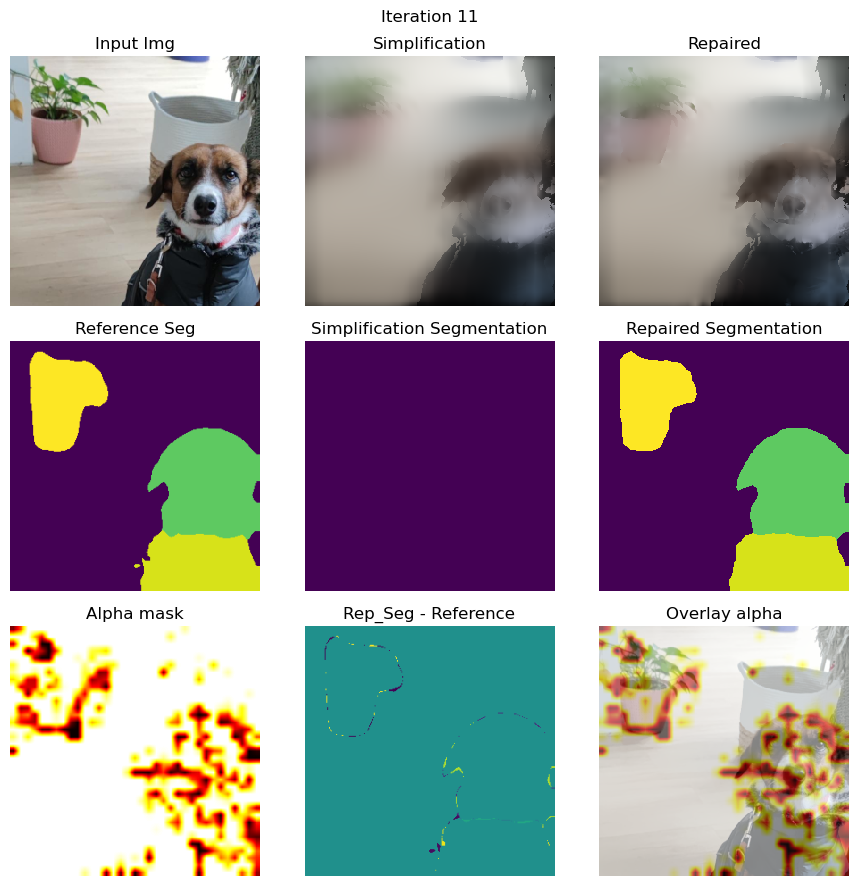

In [60]:
import visualization_utils
visualization_utils.visualizeSimplification(
    out_soft, name="cow_pres_adam", save=False)

In [ ]:
def visualize_gradients(grad_history, alpha_history, name="gradient_history", shift=100, save=False):

    # First set up the figure with subplots
    # Increased width for better layout
    matplotlib.rcParams['animation.embed_limit'] = 2**128

    fig, axes = plt.subplots(1, 3, figsize=(12, 3))

    cax = fig.add_axes([0.1, 0.8, 0.5, 0.05])
    fig.suptitle("Iteration 0")

    grad = axes[0].imshow(grad_history[0], cmap="hot")
    axes[0].set_title("Iteration 0")
    axes[0].axis('off')
    fig.colorbar(grad, cax=cax, orientation='horizontal')

    # mean
    alpha_hist = axes[1].imshow(alpha_history[0], cmap="hot", vmin=0, vmax=1)
    axes[1].set_title('Alpha step')

    # std
    axes[2].imshow(torch.stack(grad_history).std(dim=0), cmap='hot')
    axes[2].set_title('Gradient variance')

    def animate(i):
        fig.suptitle(f"Iteration {i + shift}")

        grad.set_array(grad_history[i])
        grad.set_clim(
            vmin=-abs(grad_history[i]).max(), vmax=abs(grad_history[i]).max())
        alpha_hist.set_array(alpha_history[i])
        fig.colorbar(grad, cax=cax, orientation='horizontal')
        axes[0].set_title(f"abs grads max = {abs(grad_history[i]).max()}")
        axes[0].axis('off')

        return [grad, alpha_hist]

    anim = matplotlib.animation.FuncAnimation(fig, animate,
                                              frames=len(grad_history), interval=500, blit=True)

    if save:
        # To save the animation using Pillow as a gif
        anim.save(f'{name}.gif', writer='pillow')

        FFwriter = matplotlib.animation.FFMpegWriter(fps=10)
        anim.save(f'{name}.mp4', writer=FFwriter)

    return HTML(anim.to_jshtml())